
# **TOPIC : The AI Productivity Paradox: Explaining Within-Income-Group Heterogeneity in AI-Driven Productivity Performance**


# 1. LOADING RELEVANT LIBRARIES

---



In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive
from ydata_profiling import ProfileReport
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools import add_constant
import statsmodels.formula.api as smf
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

#2. LOADING DATASETS
---


*  Data dump : https://docs.google.com/spreadsheets/d/1t09ZHxT53bQfAis4s8-5-v9WqquxnLn9UzgAeEFA6Jc/edit?usp=sharing










In [ ]:

drive.mount('/content/drive',force_remount=True)
file_path = "/content/drive/MyDrive/Python_project/dataset.xlsx"
d = pd.read_excel(file_path)
d.drop(columns=['Estimates start after'],inplace=True)
d.head()

Mounted at /content/drive


,country,AI Index
0,Afghanistan,no data
1,Albania,0.526793
2,Algeria,0.370439
3,American Samoa,no data
4,Andorra,no data


In [ ]:
# Number of rows and columns
print("Dimensions of the dataset:", d.shape)

# Rows and Columns separately
print("Number of rows:", d.shape[0])
print("Number of columns:", d.shape[1])

Dimensions of the dataset: (387, 2)
Number of rows: 387
Number of columns: 2


In [ ]:
print(d.dtypes)

country     object
AI Index    object
dtype: object


In [ ]:
aggregates = ["ASEAN-5", "Advanced economies", "Asia and Pacific",
    "Emerging market economies", "Euro area", "Europe", "European Union",
    "Latin America and the Caribbean", "Low-income countries",
    "Major advanced economies (G7)", "Middle East and Central Asia",
    "North America", "Sub-Saharan Africa (Region) "]

d = d[~d['country'].isin(aggregates)]

In [ ]:
d.replace("no data", np.nan, inplace=True)

print(d.isnull().sum())
d.head()

country       2
AI Index    207
dtype: int64


/tmp/ipykernel_568/3380590211.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  d.replace("no data", np.nan, inplace=True)


,country,AI Index
0,Afghanistan,NaN
1,Albania,0.526793
2,Algeria,0.370439
3,American Samoa,NaN
4,Andorra,NaN


In [ ]:
data_dictionary = pd.DataFrame({
    "Column Name": d.columns,
    "Data Type": d.dtypes.values,
    "Non-Null Count": d.count().values,
    "Missing Values": d.isnull().sum().values
})

print(data_dictionary)

  Column Name Data Type  Non-Null Count  Missing Values
0     country    object             370               2
1    AI Index   float64             165             207


In [ ]:
# General information
d.info()
print("\n")
# Summary statistics
d.dropna(inplace= True)
d.describe()



<class 'pandas.core.frame.DataFrame'>
Index: 372 entries, 0 to 386
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   country   370 non-null    object 
 1   AI Index  165 non-null    float64
dtypes: float64(1), object(1)
memory usage: 8.7+ KB




,AI Index
count,165.000000
mean,0.476354
std,0.151775
min,0.184437
25%,0.355359
50%,0.465410
75%,0.581696
max,0.800567


### Loading other datasets

pwt, WDI, WGI

In [ ]:
rename_map = {
    "Bahamas, The": "Bahamas",
    "Bolivia": "Bolivia (Plurinational State of)",
    "China, People's Republic of": "China",
    "Congo, Dem. Rep. of the": "D.R. of the Congo",
    "Congo, Republic of ": "Congo",
    "Czech Republic": "Czechia",
    "Gambia, The": "Gambia",
    "Hong Kong SAR": "China, Hong Kong SAR",
    "Iran": "Iran (Islamic Republic of)",
    "Korea, Republic of": "Republic of Korea",
    "Kyrgyz Republic": "Kyrgyzstan",
    "Lao P.D.R.": "Lao People's DR",
    "Moldova": "Republic of Moldova",
    "North Macedonia ": "North Macedonia",
    "Saint Vincent and the Grenadines": "St. Vincent and the Grenadines",
    "Slovak Republic": "Slovakia",
    "Syria": "Syrian Arab Republic",
    "Tanzania": "U.R. of Tanzania: Mainland",
    "Türkiye, Republic of": "Türkiye",
    "Venezuela": "Venezuela (Bolivarian Republic of)",
    "Vietnam": "Viet Nam",
}

d['country'] = d['country'].replace(rename_map)

In [ ]:

drive.mount('/content/drive',force_remount=True)
file_path = "/content/drive/MyDrive/Python_project/pwt.xlsx"
pwt = pd.read_excel(file_path, dtype = {'rtfpna': "float64",'hc':"float64"})
print(pwt.head())
print('/n')
wdi = pd.read_excel("/content/drive/MyDrive/Python_project/WDI.xlsx")
print(wdi.head())
print('/n')
wgi = pd.read_excel("/content/drive/MyDrive/Python_project/WGI.xlsx")
print(wgi.head())

Mounted at /content/drive
                country  rtfpna    hc
0                 Aruba     NaN   NaN
1                Angola    1.00  1.54
2              Anguilla     NaN   NaN
3               Albania    1.02  3.02
4  United Arab Emirates     NaN  3.30
/n
          country Subscriptions       GDP_emp   Internet Industry share  \
0     Afghanistan      0.080087  10810.381948    15.9284      13.449823   
1         Albania     22.504859  43306.514661  83.135592      23.160712   
2         Algeria     12.008684  59596.426112  76.197601      37.547655   
3  American Samoa            ..            ..         ..             ..   
4         Andorra     51.740131            ..  94.214996      12.428226   

  Mobile connectivity      RD  Service share  
0           55.547497       ..      46.37437  
1           92.997327       ..     47.664991  
2          111.606236  0.37787      45.54768  
3                  ..       ..            ..  
4          156.097259       ..     78.311023  
/n
       

In [ ]:
#joining
main=pd.merge(d,pwt,on='country',how='inner')
main.head()

,country,AI Index,rtfpna,hc
0,Albania,0.526793,1.02,3.02
1,Algeria,0.370439,NaN,2.51
2,Angola,0.259659,1.00,1.54
3,Argentina,0.473809,0.97,3.16
4,Armenia,0.492887,1.11,3.16


In [ ]:
before = set(d['country'])
after_pwt = set(main['country'])  # after merging d with pwt
dropped = before - after_pwt
print("Dropped when merging with PWT:", sorted(dropped))

Dropped when merging with PWT: ['Libya', 'Papua New Guinea', 'Timor-Leste']


In [ ]:
rename_map_wdi = {
    "Bahamas": "Bahamas, The",
    "Bolivia (Plurinational State of)": "Bolivia",
    "China, Hong Kong SAR": "Hong Kong SAR, China",
    "Congo": "Congo, Rep.",
    "Côte d'Ivoire": "Cote d'Ivoire",
    "D.R. of the Congo": "Congo, Dem. Rep.",
    "Egypt": "Egypt, Arab Rep.",
    "Gambia": "Gambia, The",
    "Iran (Islamic Republic of)": "Iran, Islamic Rep.",
    "Kyrgyzstan": "Kyrgyz Republic",
    "Lao People's DR": "Lao PDR",
    "Republic of Korea": "Korea, Rep.",
    "Republic of Moldova": "Moldova",
    "Saint Lucia": "St. Lucia",
    "Slovakia": "Slovak Republic",
    "Türkiye": "Turkiye",
    "U.R. of Tanzania: Mainland": "Tanzania",
    "Venezuela (Bolivarian Republic of)": "Venezuela, RB",
    "Yemen": "Yemen, Rep.",
}

main['country'] = main['country'].replace(rename_map_wdi)

In [ ]:

main_w=pd.merge(main,wdi,on='country',how='inner')
main_w.head()

,country,AI Index,rtfpna,hc,Subscriptions,GDP_emp,Internet,Industry share,Mobile connectivity,RD,Service share
0,Albania,0.526793,1.02,3.02,22.504859,43306.514661,83.135592,23.160712,92.997327,..,47.664991
1,Algeria,0.370439,NaN,2.51,12.008684,59596.426112,76.197601,37.547655,111.606236,0.37787,45.54768
2,Angola,0.259659,1.00,1.54,0.373669,24097.40331,37.885899,35.701247,70.051959,..,43.554416
3,Argentina,0.473809,0.97,3.16,25.358073,59860.608685,89.228972,25.172211,137.706087,0.60111,53.199074
4,Armenia,0.492887,1.11,3.16,18.545808,45895.738008,79.99663,22.880096,134.519957,0.1821,60.345032


In [ ]:
before = set(main['country'])
after = set(main_w['country'])
dropped = before - after
print("Dropped when merging with WDI:", sorted(dropped))

Dropped when merging with WDI: []


In [ ]:
final=pd.merge(main_w,wgi,on='country',how='inner')
final.head()

,country,AI Index,rtfpna,hc,Subscriptions,GDP_emp,Internet,Industry share,Mobile connectivity,RD,Service share,Government Effectiveness,Regulatory Quality
0,Albania,0.526793,1.02,3.02,22.504859,43306.514661,83.135592,23.160712,92.997327,..,47.664991,0.293429,0.063251
1,Algeria,0.370439,NaN,2.51,12.008684,59596.426112,76.197601,37.547655,111.606236,0.37787,45.54768,-0.355561,-0.785643
2,Angola,0.259659,1.00,1.54,0.373669,24097.40331,37.885899,35.701247,70.051959,..,43.554416,-0.828703,-0.904342
3,Argentina,0.473809,0.97,3.16,25.358073,59860.608685,89.228972,25.172211,137.706087,0.60111,53.199074,0.061473,-0.506513
4,Armenia,0.492887,1.11,3.16,18.545808,45895.738008,79.99663,22.880096,134.519957,0.1821,60.345032,-0.163441,0.096441


In [ ]:
before = set(main_w['country'])
after = set(final['country'])
dropped = before - after
print("Dropped when merging with WGI:", sorted(dropped))

Dropped when merging with WGI: []


#3.  FINAL DATASET


---



In [ ]:
final.head()

,country,AI Index,rtfpna,hc,Subscriptions,GDP_emp,Internet,Industry share,Mobile connectivity,RD,Service share,Government Effectiveness,Regulatory Quality
0,Albania,0.526793,1.02,3.02,22.504859,43306.514661,83.135592,23.160712,92.997327,..,47.664991,0.293429,0.063251
1,Algeria,0.370439,NaN,2.51,12.008684,59596.426112,76.197601,37.547655,111.606236,0.37787,45.54768,-0.355561,-0.785643
2,Angola,0.259659,1.00,1.54,0.373669,24097.40331,37.885899,35.701247,70.051959,..,43.554416,-0.828703,-0.904342
3,Argentina,0.473809,0.97,3.16,25.358073,59860.608685,89.228972,25.172211,137.706087,0.60111,53.199074,0.061473,-0.506513
4,Armenia,0.492887,1.11,3.16,18.545808,45895.738008,79.99663,22.880096,134.519957,0.1821,60.345032,-0.163441,0.096441


In [ ]:
low_income = [
    "Afghanistan", "Burkina Faso", "Burundi", "Central African Republic", "Chad",
    "Congo, Dem. Rep.", "Eritrea", "Ethiopia", "Gambia, The", "Guinea-Bissau",
    "Korea, Dem. People's Rep.", "Liberia", "Madagascar", "Malawi", "Mali",
    "Mozambique", "Niger", "Rwanda", "Sierra Leone", "Somalia", "South Sudan",
    "Sudan", "Syrian Arab Republic", "Uganda", "Yemen, Rep."
]

lower_middle_income = [
    "Angola", "Bangladesh", "Benin", "Bhutan", "Bolivia", "Cambodia", "Cameroon",
    "Comoros", "Congo, Rep.", "Côte d'Ivoire", "Djibouti", "Egypt, Arab Rep.",
    "Eswatini", "Ghana", "Guinea", "Haiti", "Honduras", "India", "Kenya",
    "Kiribati", "Kyrgyz Republic", "Lao PDR", "Lebanon", "Lesotho", "Mauritania",
    "Morocco", "Myanmar", "Namibia", "Nepal", "Nicaragua", "Nigeria", "Pakistan",
    "Papua New Guinea", "São Tomé and Principe", "Senegal", "Solomon Islands",
    "Tajikistan", "Tanzania", "Timor-Leste", "Togo", "Tunisia", "Uzbekistan",
    "Vanuatu", "Venezuela, RB", "West Bank and Gaza", "Zambia", "Zimbabwe"
]

upper_middle_income = [
    "Albania", "Algeria", "Argentina", "Armenia", "Azerbaijan", "Belarus",
    "Belize", "Bosnia and Herzegovina", "Botswana", "Brazil", "Cabo Verde",
    "China", "Colombia", "Cuba", "Dominica", "Dominican Republic", "Ecuador",
    "El Salvador", "Equatorial Guinea", "Fiji", "Gabon", "Georgia", "Grenada",
    "Guatemala", "Indonesia", "Iran, Islamic Rep.", "Iraq", "Jamaica", "Jordan",
    "Kazakhstan", "Kosovo", "Libya", "Malaysia", "Maldives", "Marshall Islands",
    "Mauritius", "Mexico", "Micronesia, Fed. Sts.", "Moldova", "Mongolia",
    "Montenegro", "North Macedonia", "Paraguay", "Peru", "Philippines", "Samoa",
    "Serbia", "South Africa", "Sri Lanka", "St. Lucia",
    "St. Vincent and the Grenadines", "Suriname", "Thailand", "Tonga", "Türkiye",
    "Turkmenistan", "Tuvalu", "Ukraine", "Vietnam"
]

high_income = [
    "American Samoa", "Andorra", "Antigua and Barbuda", "Aruba", "Australia",
    "Austria", "Bahamas, The", "Bahrain", "Barbados", "Belgium", "Bermuda",
    "British Virgin Islands", "Brunei Darussalam", "Bulgaria", "Canada",
    "Cayman Islands", "Channel Islands", "Chile", "Costa Rica", "Croatia",
    "Curaçao", "Cyprus", "Czechia", "Denmark", "Estonia", "Faroe Islands",
    "Finland", "France", "French Polynesia", "Germany", "Gibraltar", "Greece",
    "Greenland", "Guam", "Guyana", "Hong Kong SAR, China", "Hungary", "Iceland",
    "Ireland", "Isle of Man", "Israel", "Italy", "Japan", "Korea, Rep.",
    "Kuwait", "Latvia", "Liechtenstein", "Lithuania", "Luxembourg",
    "Macao SAR, China", "Malta", "Monaco", "Nauru", "Netherlands",
    "New Caledonia", "New Zealand", "Northern Mariana Islands", "Norway",
    "Oman", "Palau", "Panama", "Poland", "Portugal", "Puerto Rico", "Qatar",
    "Romania", "Russian Federation", "San Marino", "Saudi Arabia",
    "Seychelles", "Singapore", "Sint Maarten (Dutch part)", "Slovak Republic",
    "Slovenia", "Spain", "St. Kitts and Nevis", "St. Martin (French part)",
    "Sweden", "Switzerland", "Taiwan, China", "Trinidad and Tobago",
    "Turks and Caicos Islands", "United Arab Emirates", "United Kingdom",
    "United States", "Uruguay", "Virgin Islands (U.S.)"
]

# Build one lookup dictionary
income_map = {}
for c in low_income: income_map[c] = "Low income"
for c in lower_middle_income: income_map[c] = "Lower middle income"
for c in upper_middle_income: income_map[c] = "Upper middle income"
for c in high_income: income_map[c] = "High income"
income_map["Cote d'Ivoire"] = "Lower middle income"
income_map["Turkiye"] = "Upper middle income"
income_map["Viet Nam"] = "Upper middle income"

# Apply to your dataframe (assumes a 'country' column with country names)
final['income_group'] = final['country'].map(income_map)

# Check what didn't match
print(final[final['income_group'].isnull()]['country'].unique())

[]


# 4. ABOUT THE DATASET


---



In [ ]:
final.head()

,country,AI Index,rtfpna,hc,Subscriptions,GDP_emp,Internet,Industry share,Mobile connectivity,RD,Service share,Government Effectiveness,Regulatory Quality,income_group
0,Albania,0.526793,1.02,3.02,22.504859,43306.514661,83.135592,23.160712,92.997327,..,47.664991,0.293429,0.063251,Upper middle income
1,Algeria,0.370439,NaN,2.51,12.008684,59596.426112,76.197601,37.547655,111.606236,0.37787,45.54768,-0.355561,-0.785643,Upper middle income
2,Angola,0.259659,1.00,1.54,0.373669,24097.40331,37.885899,35.701247,70.051959,..,43.554416,-0.828703,-0.904342,Lower middle income
3,Argentina,0.473809,0.97,3.16,25.358073,59860.608685,89.228972,25.172211,137.706087,0.60111,53.199074,0.061473,-0.506513,Upper middle income
4,Armenia,0.492887,1.11,3.16,18.545808,45895.738008,79.99663,22.880096,134.519957,0.1821,60.345032,-0.163441,0.096441,Upper middle income


In [ ]:
print("Dimensions :")
print("The number of rows", final.shape[0])
print("The number of columns", final.shape[1])

Dimensions :
The number of rows 162
The number of columns 14


In [ ]:
print("Variables : ")
print(final.columns)

Variables : 
Index(['country', 'AI Index', 'rtfpna', 'hc', 'Subscriptions', 'GDP_emp',
       'Internet', 'Industry share', 'Mobile connectivity', 'RD ',
       'Service share', 'Government Effectiveness', 'Regulatory Quality ',
       'income_group'],
      dtype='object')


In [ ]:
print("Data information : ")
print(final.info())

Data information : 
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 162 entries, 0 to 161
Data columns (total 14 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   country                   162 non-null    object 
 1   AI Index                  162 non-null    float64
 2   rtfpna                    118 non-null    float64
 3   hc                        142 non-null    float64
 4   Subscriptions             162 non-null    object 
 5   GDP_emp                   162 non-null    object 
 6   Internet                  162 non-null    object 
 7   Industry share            162 non-null    object 
 8   Mobile connectivity       162 non-null    object 
 9   RD                        162 non-null    object 
 10  Service share             162 non-null    object 
 11  Government Effectiveness  162 non-null    object 
 12  Regulatory Quality        162 non-null    object 
 13  income_group              162 non-null    obj

In [ ]:
numeric_cols = ['Subscriptions', 'GDP_emp', 'Internet', 'Industry share',
                 'Mobile connectivity', 'Service share',
                 'Government Effectiveness']
final[numeric_cols] = final[numeric_cols].apply(pd.to_numeric, errors='coerce')

In [ ]:
print("Data information : ")
print(final.info())

Data information : 
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 162 entries, 0 to 161
Data columns (total 14 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   country                   162 non-null    object 
 1   AI Index                  162 non-null    float64
 2   rtfpna                    118 non-null    float64
 3   hc                        142 non-null    float64
 4   Subscriptions             148 non-null    float64
 5   GDP_emp                   156 non-null    float64
 6   Internet                  155 non-null    float64
 7   Industry share            157 non-null    float64
 8   Mobile connectivity       150 non-null    float64
 9   RD                        162 non-null    object 
 10  Service share             157 non-null    float64
 11  Government Effectiveness  162 non-null    float64
 12  Regulatory Quality        162 non-null    object 
 13  income_group              162 non-null    obj

# 5. HANDLING MISSING VALUES


---



In [ ]:
# turning missing values to null
final.replace("..", np.nan, inplace=True)
final.head()

/tmp/ipykernel_568/240769881.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  final.replace("..", np.nan, inplace=True)


,country,AI Index,rtfpna,hc,Subscriptions,GDP_emp,Internet,Industry share,Mobile connectivity,RD,Service share,Government Effectiveness,Regulatory Quality,income_group
0,Albania,0.526793,1.02,3.02,22.504859,43306.514661,83.135592,23.160712,92.997327,NaN,47.664991,0.293429,0.063251,Upper middle income
1,Algeria,0.370439,NaN,2.51,12.008684,59596.426112,76.197601,37.547655,111.606236,0.37787,45.547680,-0.355561,-0.785643,Upper middle income
2,Angola,0.259659,1.00,1.54,0.373669,24097.403310,37.885899,35.701247,70.051959,NaN,43.554416,-0.828703,-0.904342,Lower middle income
3,Argentina,0.473809,0.97,3.16,25.358073,59860.608685,89.228972,25.172211,137.706087,0.60111,53.199074,0.061473,-0.506513,Upper middle income
4,Armenia,0.492887,1.11,3.16,18.545808,45895.738008,79.996630,22.880096,134.519957,0.18210,60.345032,-0.163441,0.096441,Upper middle income


In [ ]:
# missing values
for col in final.columns:
    missing_values = final[col].isnull().sum()
    print(f"Missing values in {col}: {missing_values}")
    print(f"Percentage of missing values in {col}: {missing_values / len(final) * 100:.2f}%")
    print("\n")

Missing values in country: 0
Percentage of missing values in country: 0.00%


Missing values in AI Index: 0
Percentage of missing values in AI Index: 0.00%


Missing values in rtfpna: 44
Percentage of missing values in rtfpna: 27.16%


Missing values in hc: 20
Percentage of missing values in hc: 12.35%


Missing values in Subscriptions: 14
Percentage of missing values in Subscriptions: 8.64%


Missing values in GDP_emp: 6
Percentage of missing values in GDP_emp: 3.70%


Missing values in Internet: 7
Percentage of missing values in Internet: 4.32%


Missing values in Industry share: 5
Percentage of missing values in Industry share: 3.09%


Missing values in Mobile connectivity: 12
Percentage of missing values in Mobile connectivity: 7.41%


Missing values in RD : 83
Percentage of missing values in RD : 51.23%


Missing values in Service share: 5
Percentage of missing values in Service share: 3.09%


Missing values in Government Effectiveness: 0
Percentage of missing values in Government

In [ ]:
# missing values
m = {}
for col in final.columns:
  missing_values = final[col].isnull().sum()
  m[col] = missing_values / len(final) * 100
missing_df = pd.DataFrame(
    list(m.items()),
    columns=["Column", "Missing_Percentage"]
)

print(missing_df)

                      Column  Missing_Percentage
0                    country            0.000000
1                   AI Index            0.000000
2                     rtfpna           27.160494
3                         hc           12.345679
4              Subscriptions            8.641975
5                    GDP_emp            3.703704
6                   Internet            4.320988
7             Industry share            3.086420
8        Mobile connectivity            7.407407
9                        RD            51.234568
10             Service share            3.086420
11  Government Effectiveness            0.000000
12       Regulatory Quality             0.000000
13              income_group            0.000000


In [ ]:
# Since the missing percentage for Research and Development is greater than 50 % , we drop it
final.drop(columns="RD ",inplace=True)
# since the GDP_EMP is our main productivity variable, we cant drop the entire variable, instead we drop the countries
final.dropna(axis = 0,subset=["GDP_emp"],inplace=True)

In [ ]:
def fill_missing_by_income_group(df, column):
    for group in df['income_group'].unique():

        # Get data for this income group
        group_data = df.loc[df['income_group'] == group, column]

        # Calculate skewness
        skew = group_data.skew()

        # Choose median if skewed, otherwise mean
        if skew < -0.5 or skew > 0.5:
            value = group_data.median()
        else:
            value = group_data.mean()

        # Fill missing values for this group
        df.loc[
            (df['income_group'] == group) & (df[column].isna()),
            column
        ] = value

    return df

for col in ['Internet', 'Industry share', 'Mobile connectivity','Service share','hc','Subscriptions','rtfpna']:
  final = fill_missing_by_income_group(final, col)

In [ ]:
# TO CHECK FOR: missing values
for col in final.columns:
    missing_values = final[col].isnull().sum()
    print(f"Missing values in {col}: {missing_values}")
    print(f"Percentage of missing values in {col}: {missing_values / len(final) * 100:.2f}%")
    print("\n")

Missing values in country: 0
Percentage of missing values in country: 0.00%


Missing values in AI Index: 0
Percentage of missing values in AI Index: 0.00%


Missing values in rtfpna: 0
Percentage of missing values in rtfpna: 0.00%


Missing values in hc: 0
Percentage of missing values in hc: 0.00%


Missing values in Subscriptions: 0
Percentage of missing values in Subscriptions: 0.00%


Missing values in GDP_emp: 0
Percentage of missing values in GDP_emp: 0.00%


Missing values in Internet: 0
Percentage of missing values in Internet: 0.00%


Missing values in Industry share: 0
Percentage of missing values in Industry share: 0.00%


Missing values in Mobile connectivity: 0
Percentage of missing values in Mobile connectivity: 0.00%


Missing values in Service share: 0
Percentage of missing values in Service share: 0.00%


Missing values in Government Effectiveness: 0
Percentage of missing values in Government Effectiveness: 0.00%


Missing values in Regulatory Quality : 0
Percentage of

In [ ]:
final.shape

(156, 13)

In [ ]:
final.head()

,country,AI Index,rtfpna,hc,Subscriptions,GDP_emp,Internet,Industry share,Mobile connectivity,Service share,Government Effectiveness,Regulatory Quality,income_group
0,Albania,0.526793,1.02,3.02,22.504859,43306.514661,83.135592,23.160712,92.997327,47.664991,0.293429,0.063251,Upper middle income
1,Algeria,0.370439,0.99,2.51,12.008684,59596.426112,76.197601,37.547655,111.606236,45.547680,-0.355561,-0.785643,Upper middle income
2,Angola,0.259659,1.00,1.54,0.373669,24097.403310,37.885899,35.701247,70.051959,43.554416,-0.828703,-0.904342,Lower middle income
3,Argentina,0.473809,0.97,3.16,25.358073,59860.608685,89.228972,25.172211,137.706087,53.199074,0.061473,-0.506513,Upper middle income
4,Armenia,0.492887,1.11,3.16,18.545808,45895.738008,79.996630,22.880096,134.519957,60.345032,-0.163441,0.096441,Upper middle income


# 6. EXPLORATORY DATA ANALYSIS


---





In [ ]:



profile = ProfileReport(final, title="Data Quality Report")
profile.to_notebook_iframe()

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 682.5/682.5 kB 12.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 55.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9/9 [ydata-profiling]


/tmp/ipykernel_568/260904821.py:2: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport


Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 13/13 [00:00<00:00, 37.73it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

## Data Quality Checks

In [ ]:
#making a copy for eda specifically
df = final.copy()
df.head()

,country,AI Index,rtfpna,hc,Subscriptions,GDP_emp,Internet,Industry share,Mobile connectivity,Service share,Government Effectiveness,Regulatory Quality,income_group
0,Albania,0.526793,1.02,3.02,22.504859,43306.514661,83.135592,23.160712,92.997327,47.664991,0.293429,0.063251,Upper middle income
1,Algeria,0.370439,0.99,2.51,12.008684,59596.426112,76.197601,37.547655,111.606236,45.547680,-0.355561,-0.785643,Upper middle income
2,Angola,0.259659,1.00,1.54,0.373669,24097.403310,37.885899,35.701247,70.051959,43.554416,-0.828703,-0.904342,Lower middle income
3,Argentina,0.473809,0.97,3.16,25.358073,59860.608685,89.228972,25.172211,137.706087,53.199074,0.061473,-0.506513,Upper middle income
4,Armenia,0.492887,1.11,3.16,18.545808,45895.738008,79.996630,22.880096,134.519957,60.345032,-0.163441,0.096441,Upper middle income


In [ ]:
print("Basic dataset inspection : ")
# Check the number of rows and columns
print("Dataset dimensions:", df.shape)

# Display all column names
print("\nColumn names:")
print(df.columns.tolist())

# Check data types and non-missing observations
print("\nDataset information:")
df.info()

#check for duplicated
print("\nNumber of duplicated rows:",df.duplicated("country").sum())

# Display the first five rows
print("\nFirst five rows:")
display(df.head())

print("\nCheck Missing Values: ")
missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})

display(missing_summary.sort_values(
    by="Missing Percentage",
    ascending=False
))


Basic dataset inspection : 
Dataset dimensions: (156, 13)

Column names:
['country', 'AI Index', 'rtfpna', 'hc', 'Subscriptions', 'GDP_emp', 'Internet', 'Industry share', 'Mobile connectivity', 'Service share', 'Government Effectiveness', 'Regulatory Quality ', 'income_group']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
Index: 156 entries, 0 to 161
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   country                   156 non-null    object 
 1   AI Index                  156 non-null    float64
 2   rtfpna                    156 non-null    float64
 3   hc                        156 non-null    float64
 4   Subscriptions             156 non-null    float64
 5   GDP_emp                   156 non-null    float64
 6   Internet                  156 non-null    float64
 7   Industry share            156 non-null    float64
 8   Mobile connectivity       156 non-null    flo

,country,AI Index,rtfpna,hc,Subscriptions,GDP_emp,Internet,Industry share,Mobile connectivity,Service share,Government Effectiveness,Regulatory Quality,income_group
0,Albania,0.526793,1.02,3.02,22.504859,43306.514661,83.135592,23.160712,92.997327,47.664991,0.293429,0.063251,Upper middle income
1,Algeria,0.370439,0.99,2.51,12.008684,59596.426112,76.197601,37.547655,111.606236,45.547680,-0.355561,-0.785643,Upper middle income
2,Angola,0.259659,1.00,1.54,0.373669,24097.403310,37.885899,35.701247,70.051959,43.554416,-0.828703,-0.904342,Lower middle income
3,Argentina,0.473809,0.97,3.16,25.358073,59860.608685,89.228972,25.172211,137.706087,53.199074,0.061473,-0.506513,Upper middle income
4,Armenia,0.492887,1.11,3.16,18.545808,45895.738008,79.996630,22.880096,134.519957,60.345032,-0.163441,0.096441,Upper middle income



Check Missing Values: 


,Missing Count,Missing Percentage
country,0,0.0
AI Index,0,0.0
rtfpna,0,0.0
hc,0,0.0
Subscriptions,0,0.0
GDP_emp,0,0.0
Internet,0,0.0
Industry share,0,0.0
Mobile connectivity,0,0.0
Service share,0,0.0


## Descriptive Statistics

In [ ]:
print("Descriptive Statistics : ")
numeric_cols = df.select_dtypes(
    include=np.number
).columns.tolist()

descriptive_stats = df[numeric_cols].describe().T

descriptive_stats["Variance"] = (
    df[numeric_cols].var()
)

descriptive_stats["Skewness"] = (
    df[numeric_cols].skew()
)

descriptive_stats["Kurtosis"] = (
    df[numeric_cols].kurtosis()
)

display(descriptive_stats.round(3))

Descriptive Statistics : 


,count,mean,std,min,25%,50%,75%,max,Variance,Skewness,Kurtosis
AI Index,156.0,0.484,0.150,0.184,0.366,0.471,0.584,0.801,2.300000e-02,0.326,-0.826
rtfpna,156.0,0.995,0.039,0.890,0.980,0.990,1.000,1.210,2.000000e-03,1.802,8.772
hc,156.0,2.757,0.671,1.260,2.138,2.850,3.272,3.990,4.500000e-01,-0.336,-0.783
Subscriptions,156.0,17.953,15.587,0.000,1.816,15.169,31.884,48.669,2.429440e+02,0.354,-1.312
GDP_emp,156.0,59036.680,49430.656,2421.477,19048.457,45861.681,87752.737,264776.518,2.443390e+09,1.293,2.052
Internet,156.0,71.494,25.488,7.172,54.220,81.601,91.278,100.000,6.496620e+02,-0.956,-0.283
Industry share,156.0,26.964,10.938,2.086,20.091,25.488,32.439,69.301,1.196430e+02,1.089,2.212
Mobile connectivity,156.0,120.953,39.807,47.500,100.731,120.711,134.677,361.049,1.584608e+03,2.162,11.111
Service share,156.0,55.302,11.563,18.767,47.618,56.283,62.615,91.438,1.336990e+02,0.014,0.332
Government Effectiveness,156.0,0.135,0.931,-2.011,-0.600,0.054,0.752,2.262,8.670000e-01,0.247,-0.608


income_group
High income            56
Upper middle income    45
Lower middle income    38
Low income             17
Name: count, dtype: int64


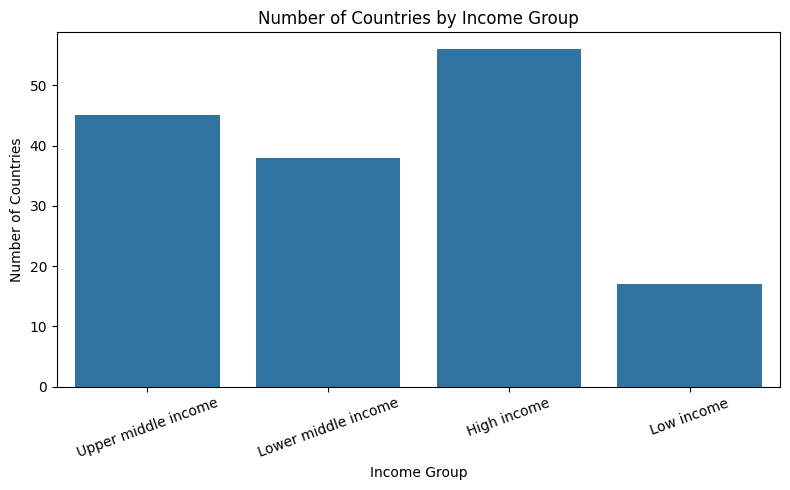

In [ ]:
# Number of countries in each Income group
income_counts = df["income_group"].value_counts()

print(income_counts)

plt.figure(figsize=(8, 5))
sns.countplot(data=final, x="income_group")

plt.title("Number of Countries by Income Group")
plt.xlabel("Income Group")
plt.ylabel("Number of Countries")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [ ]:
# Summarise AI readiness separately within each income group
ai_group_stats = (
    df.groupby("income_group")["AI Index"]
      .agg(
          count="count",
          mean="mean",
          std="std",
          median="median",
          minimum="min",
          maximum="max"
      )
)

# Calculate the range and interquartile range
ai_group_stats["range"] = (
    ai_group_stats["maximum"] - ai_group_stats["minimum"]
)

ai_group_stats["IQR"] = (
    df.groupby("income_group")["AI Index"].quantile(0.75)
    - df.groupby("income_group")["AI Index"].quantile(0.25)
)

print(ai_group_stats.round(3))

                     count   mean    std  median  minimum  maximum  range  \
income_group                                                                
High income             56  0.639  0.100   0.646    0.424    0.801  0.376   
Low income              17  0.302  0.060   0.298    0.184    0.437  0.253   
Lower middle income     38  0.359  0.060   0.359    0.233    0.493  0.260   
Upper middle income     45  0.466  0.073   0.481    0.270    0.635  0.366   

                       IQR  
income_group                
High income          0.153  
Low income           0.083  
Lower middle income  0.071  
Upper middle income  0.081  


## Understanding the Dependent Variable - AI readiness

In [ ]:

# Top 10 countries globally by AI readiness

top_global_ai = (
    df[["country", "income_group", "AI Index"]]
    .dropna(subset=["AI Index"])
    .sort_values("AI Index", ascending=False)
    .head(10)
    .reset_index(drop=True)
)

top_global_ai.index = top_global_ai.index + 1
top_global_ai.index.name = "Rank"

display(top_global_ai.round({"AI Index": 3}))


,country,income_group,AI Index
Rank,,,
1,Singapore,High income,0.801
2,Denmark,High income,0.779
3,United States,High income,0.771
4,Netherlands,High income,0.766
5,Estonia,High income,0.764
6,Finland,High income,0.758
7,Switzerland,High income,0.757
8,New Zealand,High income,0.754
9,Germany,High income,0.753


In [ ]:

# Top 5 countries in each income group by AI readiness

top_by_income = (
    df[["country", "income_group", "AI Index"]]
    .dropna(subset=["AI Index"])
    .sort_values(
        ["income_group", "AI Index"],
        ascending=[True, False]
    )
    .groupby("income_group", sort=False)
    .head(5)
    .sort_values(["income_group", "AI Index"], ascending=[True, False])
    .reset_index(drop=True)
)

display(top_by_income.round({"AI Index": 3}))


,country,income_group,AI Index
0,Singapore,High income,0.801
1,Denmark,High income,0.779
2,United States,High income,0.771
3,Netherlands,High income,0.766
4,Estonia,High income,0.764
5,Rwanda,Low income,0.437
6,Liberia,Low income,0.370
7,"Gambia, The",Low income,0.360
8,Uganda,Low income,0.354
9,Malawi,Low income,0.340


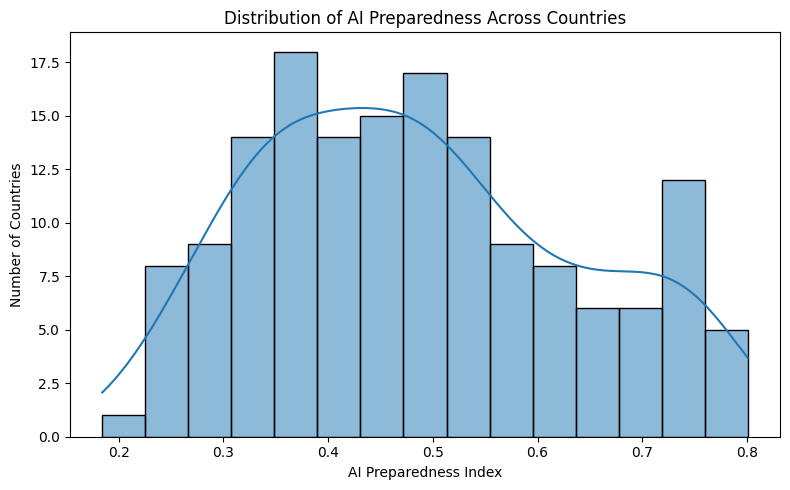

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=final,
    x="AI Index",
    bins=15,
    kde=True
)

plt.title("Distribution of AI Preparedness Across Countries")
plt.xlabel("AI Preparedness Index")
plt.ylabel("Number of Countries")

plt.tight_layout()
plt.show()


AI preparedness scores vary across a fairly broad range, from approximately 0.18 to 0.80, with the largest concentration of observations around 0.45–0.55.

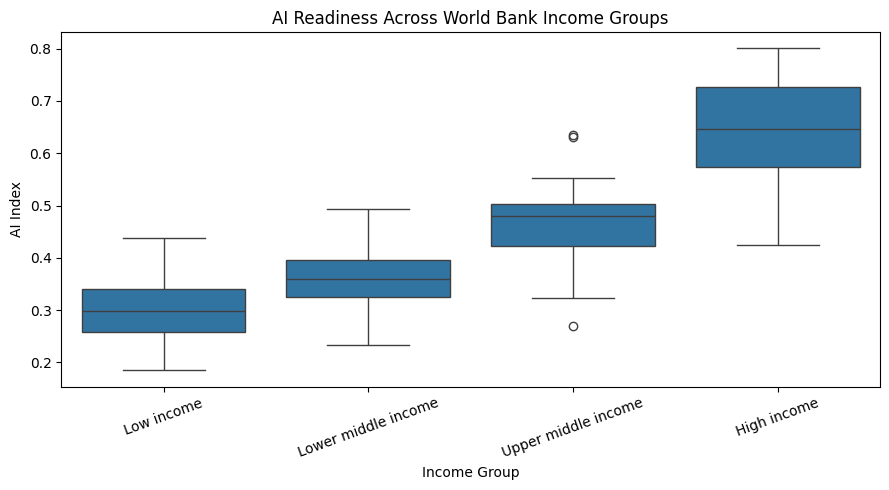

In [ ]:
# Define the correct order
income_order = [
    "Low income",
    "Lower middle income",
    "Upper middle income",
    "High income"
]

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="income_group",
    y="AI Index",
    order=income_order
)

plt.title("AI Readiness Across World Bank Income Groups")
plt.xlabel("Income Group")
plt.ylabel("AI Index")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [ ]:
#outlier analysis
def find_outliers(group):
    q1 = group["AI Index"].quantile(0.25)
    q3 = group["AI Index"].quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    return group[
        (group["AI Index"] < lower_bound) |
        (group["AI Index"] > upper_bound)
    ].assign(
        lower_bound=lower_bound,
        upper_bound=upper_bound
    )

outliers = (
    df.groupby("income_group", group_keys=False)
      .apply(find_outliers)
)

print(
    outliers[
        ['country', "income_group", "AI Index",
         "lower_bound", "upper_bound"]
    ].to_string(index=False)
)

 country        income_group  AI Index  lower_bound  upper_bound
   China Upper middle income  0.635454     0.301027     0.625293
    Iraq Upper middle income  0.269836     0.301027     0.625293
Malaysia Upper middle income  0.632026     0.301027     0.625293


/tmp/ipykernel_568/2015551273.py:20: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(find_outliers)


Here we have identified 3 outliers - China and Malaysia are slightly above the upper threshold, while Iraq is below the lower threshold.These countries have AI readiness scores that differ from the typical range of the upper-middle-income group in your sample.That is relevant to our objective: understanding why countries within the same income group differ in AI readiness and hence we keep the outliers

## Understanding our explanatory variables

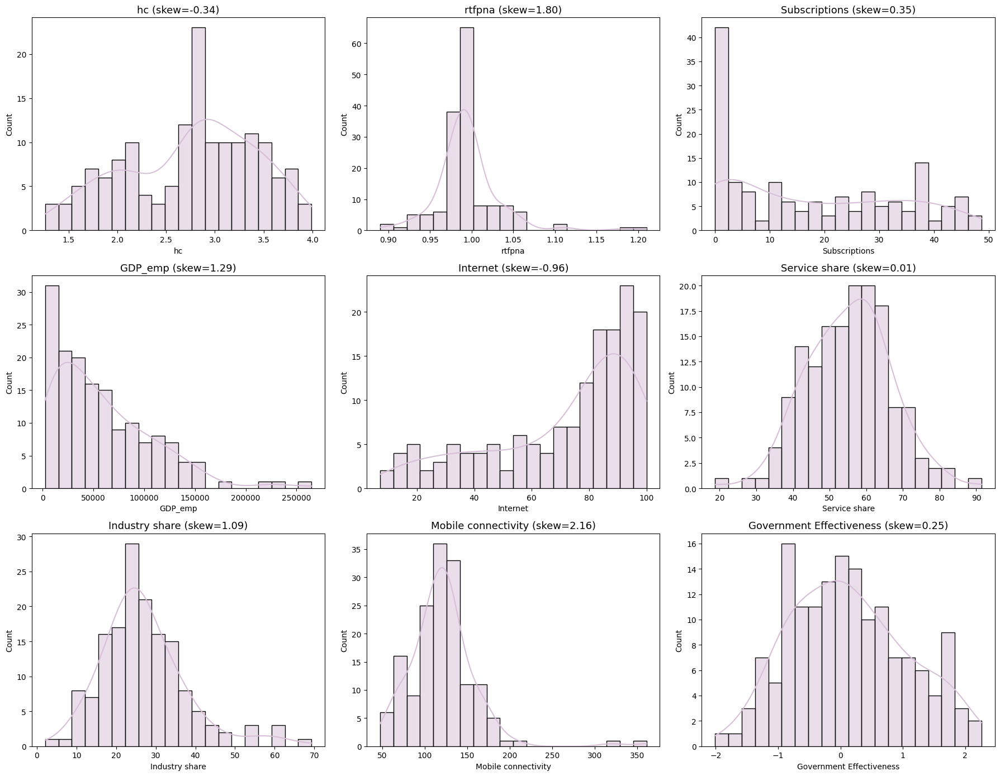

In [ ]:
X = ["hc","rtfpna","Subscriptions","GDP_emp","Internet","Service share","Industry share","Mobile connectivity","Government Effectiveness"]

fig, axes = plt.subplots(3, 3, figsize=(18,14))
for ax, c in zip(axes.flatten(), X):
    sns.histplot(df[c], bins=20, kde=True, ax=ax, color="thistle")
    ax.set_title(f"{c} (skew={df[c].skew():.2f})", fontsize=13)
plt.tight_layout(); plt.show()

- GDP_emp and Mobile connectivity need log transformation

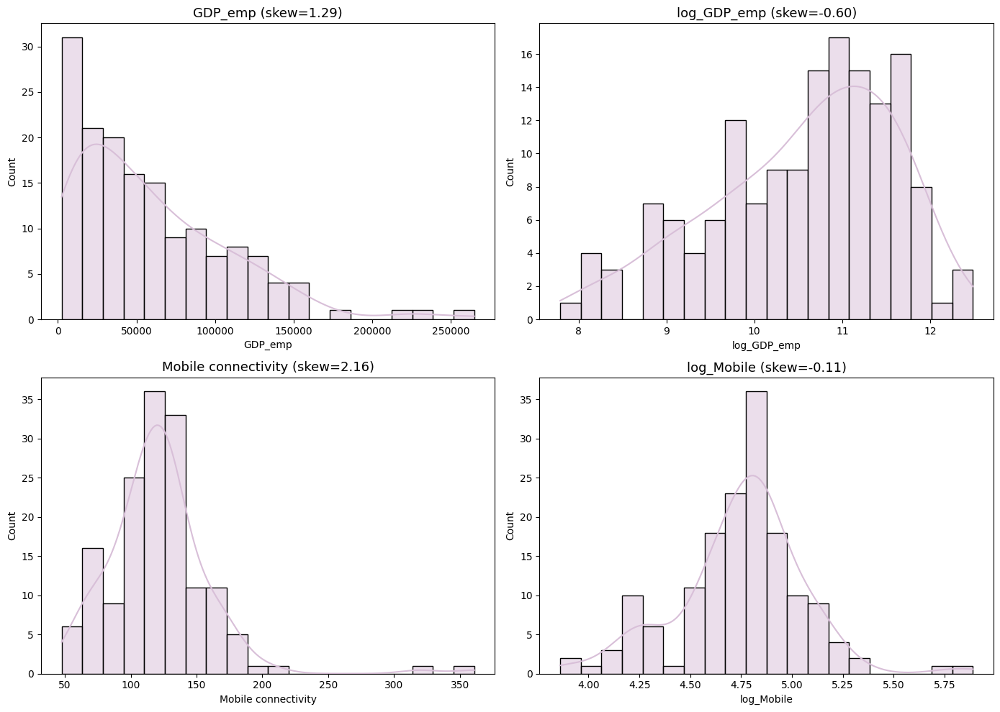

In [ ]:
df["log_GDP_emp"] = np.log(df["GDP_emp"])
df["log_Mobile"] = np.log(df["Mobile connectivity"])

fig, axes = plt.subplots(2, 2, figsize=(14,10))
pairs = [("GDP_emp","log_GDP_emp"), ("Mobile connectivity","log_Mobile")]
for i, (raw, lg) in enumerate(pairs):
    for j, c in enumerate([raw, lg]):
        sns.histplot(df[c], bins=20, kde=True, ax=axes[i][j], color="thistle")
        axes[i][j].set_title(f"{c} (skew={df[c].skew():.2f})", fontsize=13)
plt.tight_layout(); plt.show()

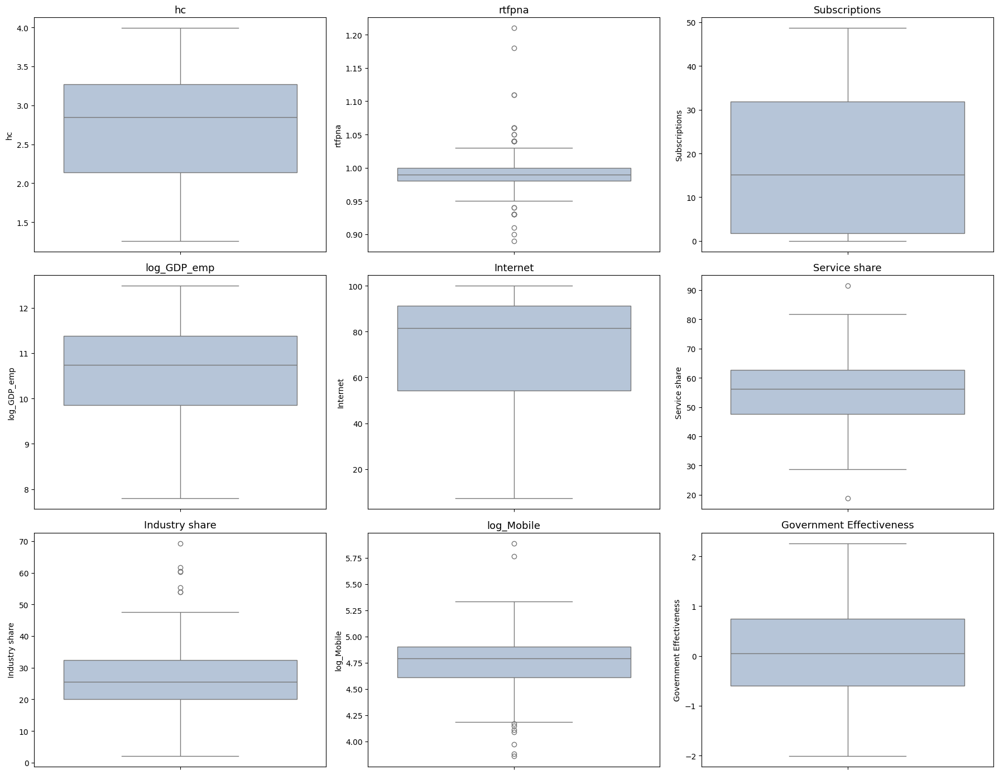

In [ ]:
X = ["hc","rtfpna","Subscriptions","log_GDP_emp","Internet","Service share","Industry share","log_Mobile","Government Effectiveness"]

fig, axes = plt.subplots(3, 3, figsize=(18,14))
for ax, c in zip(axes.flatten(), X):
    sns.boxplot(y=df[c], ax=ax, color="lightsteelblue")
    ax.set_title(c, fontsize=13)
plt.tight_layout(); plt.show()

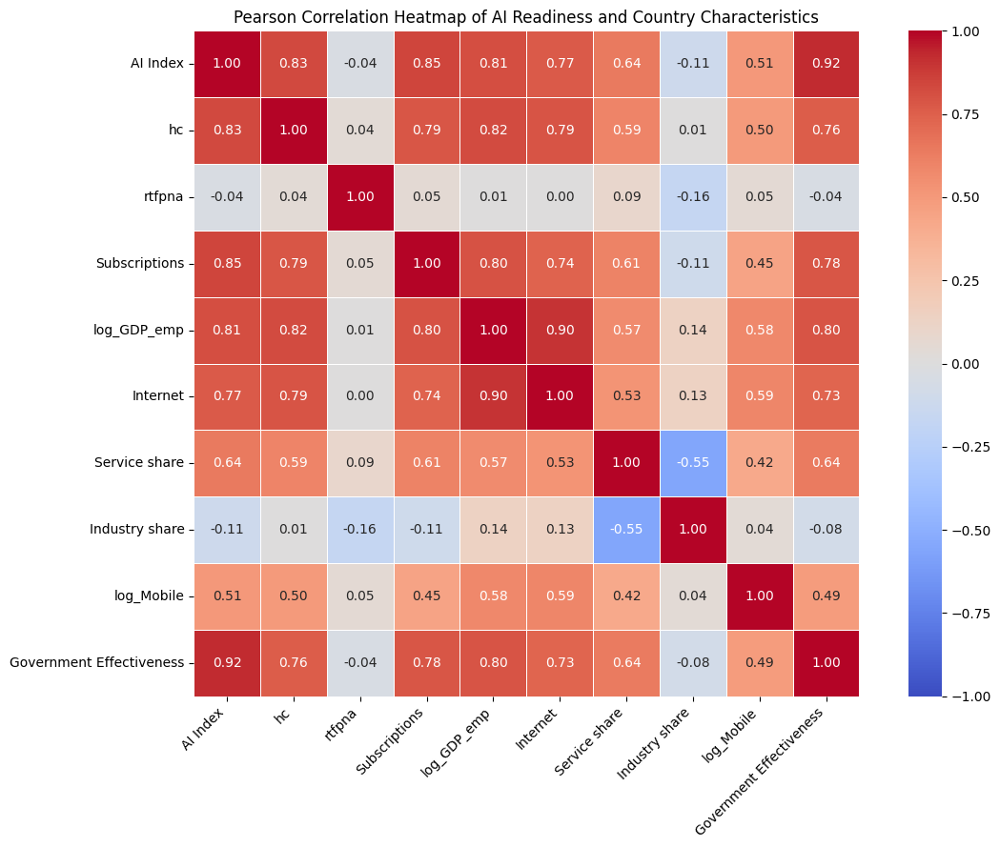

In [ ]:
corr_vars = [
    "AI Index",
    "hc",
    "rtfpna",
    "Subscriptions",
    "log_GDP_emp",
    "Internet",
    "Service share",
    "Industry share",
    "log_Mobile",
    "Government Effectiveness"
]
corr_pearson = df[corr_vars].corr(method="pearson")

plt.figure(figsize=(12, 9))
sns.heatmap(corr_pearson, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, center=0, square=True, linewidths=0.5)
plt.title("Pearson Correlation Heatmap of AI Readiness and Country Characteristics")
plt.xticks(rotation=45, ha="right"); plt.yticks(rotation=0)
plt.tight_layout(); plt.show()

- dropping industry share and rtfpna because of low correlation

In [ ]:
import pandas as pd

corr_vars = [
    "AI Index",
    "hc",
    "log_GDP_emp",
    "Subscriptions",
    "Internet",
    "Service share",
    "Mobile connectivity",
    "Government Effectiveness"
]

for group, data in df.groupby("income_group"):
    corr_matrix = data[corr_vars].corr(method="pearson")

    print(f"\n{group} (n={len(data)})")
    display(corr_matrix.round(2))


High income (n=56)


,AI Index,hc,log_GDP_emp,Subscriptions,Internet,Service share,Mobile connectivity,Government Effectiveness
AI Index,1.00,0.64,0.50,0.60,0.39,0.45,0.03,0.85
hc,0.64,1.00,0.24,0.44,0.15,0.24,-0.10,0.49
log_GDP_emp,0.50,0.24,1.00,0.26,0.52,-0.09,0.03,0.59
Subscriptions,0.60,0.44,0.26,1.00,0.04,0.34,-0.11,0.43
Internet,0.39,0.15,0.52,0.04,1.00,-0.08,0.11,0.52
Service share,0.45,0.24,-0.09,0.34,-0.08,1.00,0.21,0.34
Mobile connectivity,0.03,-0.10,0.03,-0.11,0.11,0.21,1.00,0.06
Government Effectiveness,0.85,0.49,0.59,0.43,0.52,0.34,0.06,1.00



Low income (n=17)


,AI Index,hc,log_GDP_emp,Subscriptions,Internet,Service share,Mobile connectivity,Government Effectiveness
AI Index,1.00,0.39,0.28,0.30,0.38,0.48,0.28,0.76
hc,0.39,1.00,0.07,-0.23,-0.18,0.16,-0.09,0.18
log_GDP_emp,0.28,0.07,1.00,0.53,0.59,0.11,0.49,0.38
Subscriptions,0.30,-0.23,0.53,1.00,0.59,0.44,0.61,0.50
Internet,0.38,-0.18,0.59,0.59,1.00,0.44,0.55,0.16
Service share,0.48,0.16,0.11,0.44,0.44,1.00,0.49,0.35
Mobile connectivity,0.28,-0.09,0.49,0.61,0.55,0.49,1.00,0.16
Government Effectiveness,0.76,0.18,0.38,0.50,0.16,0.35,0.16,1.00



Lower middle income (n=38)


,AI Index,hc,log_GDP_emp,Subscriptions,Internet,Service share,Mobile connectivity,Government Effectiveness
AI Index,1.00,0.40,0.28,0.39,0.47,0.18,0.24,0.71
hc,0.40,1.00,0.20,0.42,0.28,0.17,-0.08,0.11
log_GDP_emp,0.28,0.20,1.00,0.46,0.57,0.35,-0.02,0.35
Subscriptions,0.39,0.42,0.46,1.00,0.39,0.33,0.29,0.19
Internet,0.47,0.28,0.57,0.39,1.00,0.14,0.01,0.31
Service share,0.18,0.17,0.35,0.33,0.14,1.00,-0.04,0.20
Mobile connectivity,0.24,-0.08,-0.02,0.29,0.01,-0.04,1.00,0.12
Government Effectiveness,0.71,0.11,0.35,0.19,0.31,0.20,0.12,1.00



Upper middle income (n=45)


,AI Index,hc,log_GDP_emp,Subscriptions,Internet,Service share,Mobile connectivity,Government Effectiveness
AI Index,1.00,0.38,0.10,0.34,0.50,0.10,0.04,0.60
hc,0.38,1.00,0.29,0.23,0.41,0.15,-0.06,0.29
log_GDP_emp,0.10,0.29,1.00,0.28,0.43,-0.16,-0.03,-0.06
Subscriptions,0.34,0.23,0.28,1.00,0.43,0.08,-0.18,0.16
Internet,0.50,0.41,0.43,0.43,1.00,-0.19,-0.11,0.25
Service share,0.10,0.15,-0.16,0.08,-0.19,1.00,0.10,0.44
Mobile connectivity,0.04,-0.06,-0.03,-0.18,-0.11,0.10,1.00,0.23
Government Effectiveness,0.60,0.29,-0.06,0.16,0.25,0.44,0.23,1.00


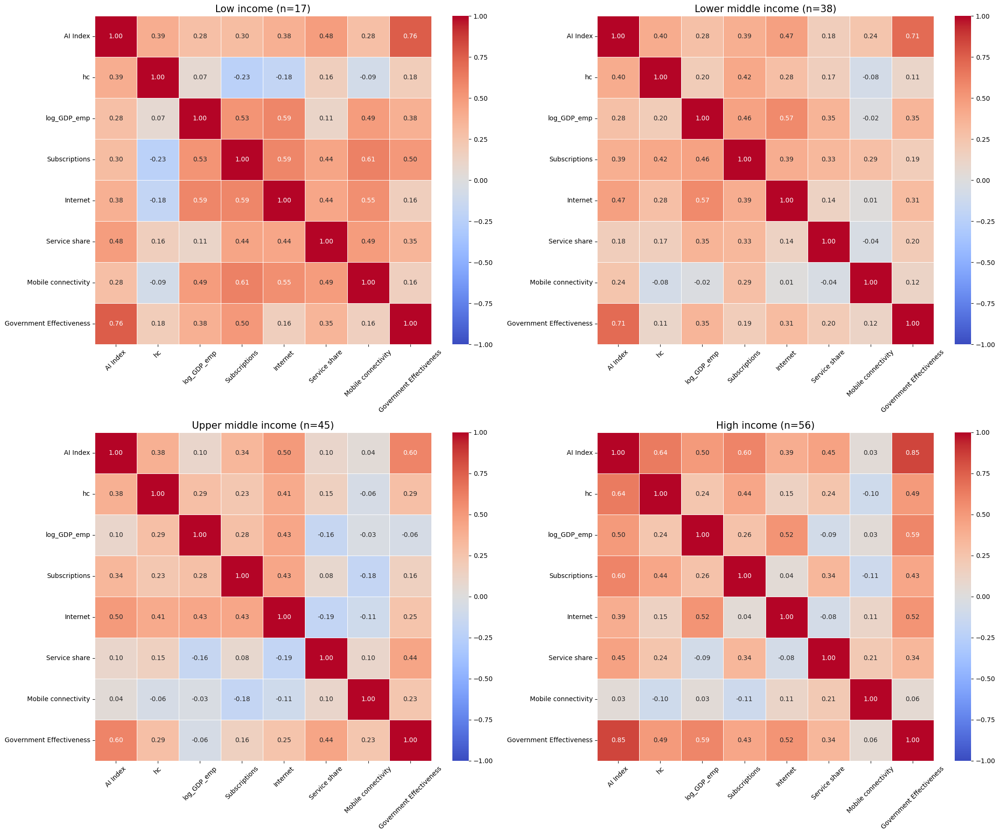

In [ ]:
groups = ["Low income","Lower middle income","Upper middle income","High income"]
fig, axes = plt.subplots(2, 2, figsize=(22,18))
for ax, g in zip(axes.flatten(), groups):
    d = df[df["income_group"] == g]
    sns.heatmap(d[corr_vars].corr(method="pearson"), annot=True, fmt=".2f", cmap="coolwarm",
                vmin=-1, vmax=1, linewidths=.5, annot_kws={"size":10}, ax=ax)
    ax.set_title(f"{g} (n={len(d)})", fontsize=15)
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

In [ ]:


X = ["hc","log_GDP_emp","Subscriptions","Internet","Service share","log_Mobile","Government Effectiveness"]

def vif(data, cols):
    d = add_constant(data[cols])
    return pd.Series([variance_inflation_factor(d.values, i) for i in range(1, d.shape[1])], index=cols)

print("ALL COUNTRIES")
print(vif(df, X).round(2))
print("\n")
for g in df["income_group"].unique():
    print(g)
    print(vif(df[df["income_group"]==g], X).round(2))
    print("\n")

ALL COUNTRIES
hc                          3.93
log_GDP_emp                 7.74
Subscriptions               3.74
Internet                    5.72
Service share               1.84
log_Mobile                  1.61
Government Effectiveness    3.61
dtype: float64


Upper middle income
hc                          1.35
log_GDP_emp                 1.35
Subscriptions               1.30
Internet                    1.92
Service share               1.50
log_Mobile                  1.11
Government Effectiveness    1.62
dtype: float64


Lower middle income
hc                          1.29
log_GDP_emp                 1.90
Subscriptions               1.93
Internet                    1.64
Service share               1.29
log_Mobile                  1.28
Government Effectiveness    1.20
dtype: float64


High income
hc                          1.48
log_GDP_emp                 1.95
Subscriptions               1.53
Internet                    1.71
Service share               1.54
log_Mobile               

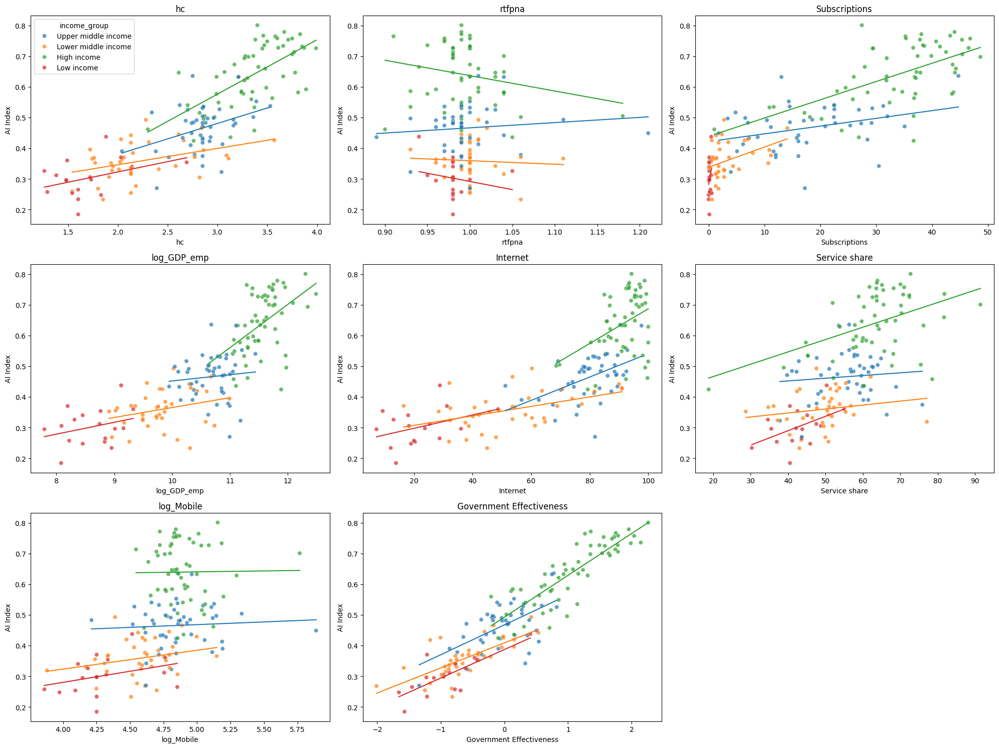

In [ ]:
pal = {"Low income":"#d62728","Lower middle income":"#ff7f0e","Upper middle income":"#1f77b4","High income":"#2ca02c"}
X = ["hc","rtfpna","Subscriptions","log_GDP_emp","Internet","Service share","log_Mobile","Government Effectiveness"]

fig, axes = plt.subplots(3, 3, figsize=(20,15))
for ax, c in zip(axes.flatten(), X):
    sns.scatterplot(data=df, x=c, y="AI Index", hue="income_group", palette=pal, alpha=0.7, ax=ax, legend=(c==X[0]))
    for g, sub in df.groupby("income_group"):
        sns.regplot(data=sub, x=c, y="AI Index", scatter=False, ci=None, color=pal[g], ax=ax, line_kws={"lw":1.5})
    ax.set_title(c)
axes.flatten()[-1].axis("off")
plt.tight_layout(); plt.show()

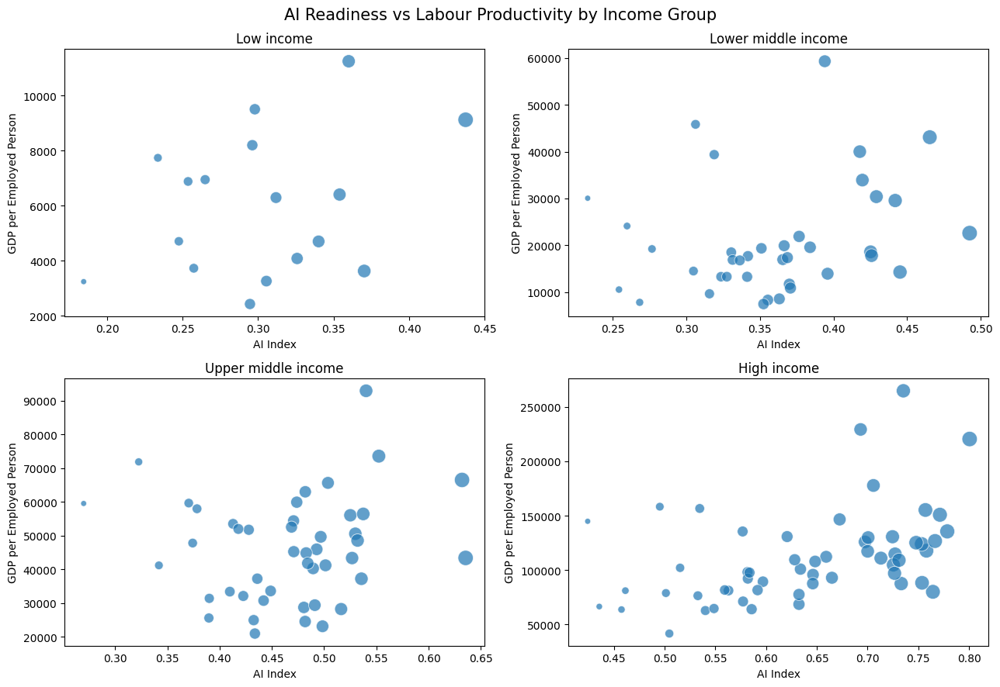

In [ ]:


income_order = [
    "Low income",
    "Lower middle income",
    "Upper middle income",
    "High income"
]

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
axes = axes.flatten()

for ax, group in zip(axes, income_order):
    subset = df[df["income_group"] == group]

    sns.scatterplot(
        data=subset,
        x="AI Index",
        y="GDP_emp",
        size="AI Index",
        sizes=(30, 200),
        alpha=0.7,
        legend=False,
        ax=ax
    )

    ax.set_title(group)
    ax.set_xlabel("AI Index")
    ax.set_ylabel("GDP per Employed Person")

fig.suptitle("AI Readiness vs Labour Productivity by Income Group", fontsize=15)
plt.tight_layout()
plt.show()

In [ ]:
df["log_GDP_emp"] = np.log(df["GDP_emp"])

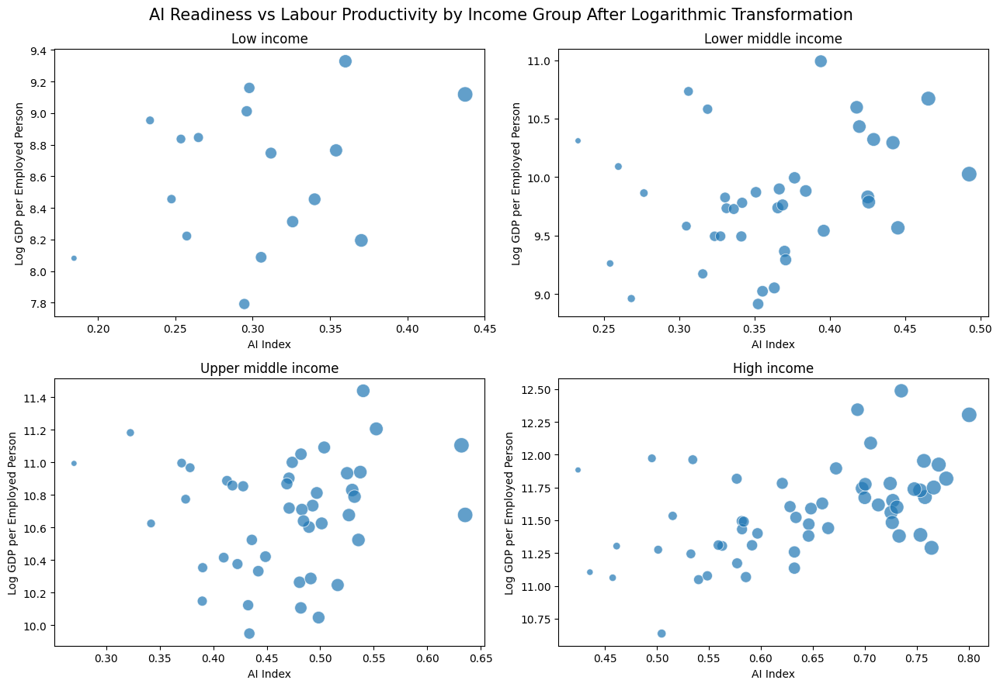

In [ ]:
income_order = [
    "Low income",
    "Lower middle income",
    "Upper middle income",
    "High income"
]

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
axes = axes.flatten()

for ax, group in zip(axes, income_order):
    subset = df[df["income_group"] == group]

    sns.scatterplot(
        data=subset,
        x="AI Index",
        y="log_GDP_emp",
        size="AI Index",
        sizes=(30, 200),
        alpha=0.7,
        legend=False,
        ax=ax
    )

    ax.set_title(group)
    ax.set_xlabel("AI Index")
    ax.set_ylabel("Log GDP per Employed Person")

fig.suptitle("AI Readiness vs Labour Productivity by Income Group After Logarithmic Transformation", fontsize=15)
plt.tight_layout()
plt.show()

# Understanding within group disparities using Z score

In [ ]:
# Overall z-score (relative to all 156 countries)
df["AI_z"] = (df["AI Index"] - df["AI Index"].mean()) / df["AI Index"].std()

# Within-group z-score (relative to income-group peers)
df["AI_z_group"] = df.groupby("income_group")["AI Index"].transform(lambda s: (s - s.mean()) / s.std())

print(df.groupby("income_group")[["AI_z","AI_z_group"]].agg(["mean","std"]).round(2))

                     AI_z       AI_z_group     
                     mean   std       mean  std
income_group                                   
High income          1.03  0.66       -0.0  1.0
Low income          -1.21  0.40        0.0  1.0
Lower middle income -0.83  0.40        0.0  1.0
Upper middle income -0.12  0.48        0.0  1.0


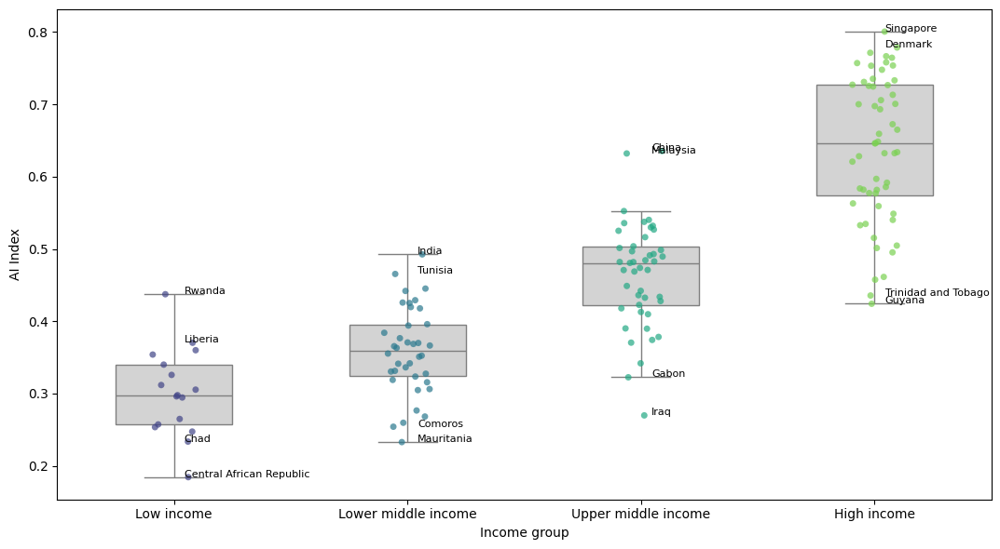

In [ ]:

order = ["Low income","Lower middle income","Upper middle income","High income"]
pal = dict(zip(order, sns.color_palette("viridis", 4)))
d = df.dropna(subset=["AI Index","AI_z_group"]).query("income_group in @order")

fig, ax = plt.subplots(figsize=(11,6))
sns.boxplot(data=d, x="income_group", y="AI Index", order=order, showfliers=False,
            color="lightgrey", width=0.5, ax=ax, zorder=1)
sns.stripplot(data=d, x="income_group", y="AI Index", order=order, hue="income_group",
              hue_order=order, palette=pal, alpha=0.7, legend=False, ax=ax, zorder=2)

ext = pd.concat([g.nlargest(2,"AI_z_group") for _, g in d.groupby("income_group")] +
                [g.nsmallest(2,"AI_z_group") for _, g in d.groupby("income_group")]).drop_duplicates("country")
for _, r in ext.iterrows():
    ax.annotate(r["country"], (order.index(r["income_group"]), r["AI Index"]),
                fontsize=8, xytext=(8,0), textcoords="offset points")

ax.set_xlabel("Income group"); plt.tight_layout(); plt.show()

In [ ]:
s = df.sort_values("AI_z_group")
print(pd.concat([s.groupby("income_group").head(3), s.groupby("income_group").tail(3)])
        .sort_values(["income_group","AI_z_group"])[["income_group","country","AI Index","AI_z_group"]].round(2))

            income_group                         country  AI Index  AI_z_group
63           High income                          Guyana      0.42       -2.16
148          High income             Trinidad and Tobago      0.44       -2.04
8            High income                    Bahamas, The      0.46       -1.82
155          High income                   United States      0.77        1.32
42           High income                         Denmark      0.78        1.40
133          High income                       Singapore      0.80        1.62
29            Low income        Central African Republic      0.18       -1.95
30            Low income                            Chad      0.23       -1.13
35            Low income                Congo, Dem. Rep.      0.25       -0.90
55            Low income                     Gambia, The      0.36        0.96
88            Low income                         Liberia      0.37        1.13
125           Low income                          Rw

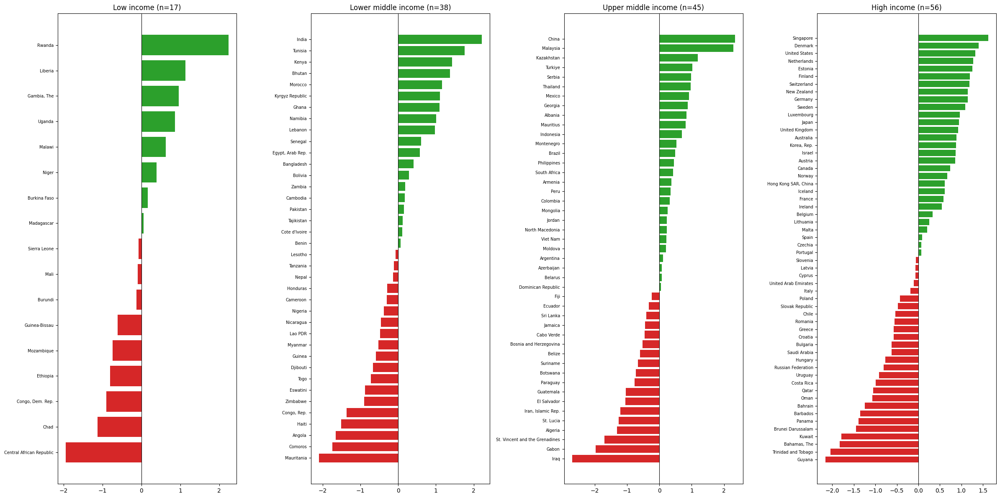

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(24,12))
for ax, g in zip(axes, order):
    d_ = df[df["income_group"]==g].sort_values("AI_z_group")
    ax.barh(d_["country"], d_["AI_z_group"], color=np.where(d_["AI_z_group"]>0, "#2ca02c", "#d62728"))
    ax.axvline(0, color="k", lw=0.8); ax.set_title(f"{g} (n={len(d_)})"); ax.tick_params(axis="y", labelsize=7)
plt.tight_layout(); plt.show()

In [ ]:

reg_df = df.copy()
reg_df.columns = reg_df.columns.str.strip()

print("Dataset shape:", reg_df.shape)
print("\nColumns:")
print(reg_df.columns.tolist())

print("\nIncome group counts:")
print(reg_df["income_group"].value_counts())

print("\nMissing values:")
print(reg_df.isnull().sum())

print("\nDuplicate countries:",
      reg_df["country"].duplicated().sum())

print("\nSummary of candidate variables:")
print(reg_df[
    ["AI Index", "GDP_emp", "log_GDP_emp",
     "hc", "Subscriptions", "Internet"]
].describe().round(3))

Dataset shape: (156, 17)

Columns:
['country', 'AI Index', 'rtfpna', 'hc', 'Subscriptions', 'GDP_emp', 'Internet', 'Industry share', 'Mobile connectivity', 'Service share', 'Government Effectiveness', 'Regulatory Quality', 'income_group', 'log_GDP_emp', 'log_Mobile', 'AI_z', 'AI_z_group']

Income group counts:
income_group
High income            56
Upper middle income    45
Lower middle income    38
Low income             17
Name: count, dtype: int64

Missing values:
country                     0
AI Index                    0
rtfpna                      0
hc                          0
Subscriptions               0
GDP_emp                     0
Internet                    0
Industry share              0
Mobile connectivity         0
Service share               0
Government Effectiveness    0
Regulatory Quality          0
income_group                0
log_GDP_emp                 0
log_Mobile                  0
AI_z                        0
AI_z_group                  0
dtype: int64

Dupl

In [ ]:

numeric_cols = [
    "AI Index",
    "hc",
    "Subscriptions",
    "GDP_emp",
    "log_GDP_emp",
    "Internet",
    "Mobile connectivity",
    "log_Mobile",
    "Service share",
    "Government Effectiveness",
]

for col in numeric_cols:
    reg_df[col] = pd.to_numeric(reg_df[col], errors="coerce")

print(reg_df[numeric_cols].dtypes)
print("\nMissing values after conversion:")
print(reg_df[numeric_cols].isna().sum())


AI Index                    float64
hc                          float64
Subscriptions               float64
GDP_emp                     float64
log_GDP_emp                 float64
Internet                    float64
Mobile connectivity         float64
log_Mobile                  float64
Service share               float64
Government Effectiveness    float64
dtype: object

Missing values after conversion:
AI Index                    0
hc                          0
Subscriptions               0
GDP_emp                     0
log_GDP_emp                 0
Internet                    0
Mobile connectivity         0
log_Mobile                  0
Service share               0
Government Effectiveness    0
dtype: int64


In [ ]:

formula_full = (
    'Q("AI Index") ~ hc + Subscriptions + '
    'log_GDP_emp + Internet + log_Mobile + '
    'Q("Service share") + '
    'Q("Government Effectiveness") + '
    'C(income_group)'
)

model_full = smf.ols(
    formula=formula_full,
    data=reg_df
).fit(cov_type="HC3")

print("Observations:", int(model_full.nobs))
print("Number of coefficients:", len(model_full.params))
print("Residual degrees of freedom:", model_full.df_resid)
print("R-squared:", model_full.rsquared)
print("Adjusted R-squared:", model_full.rsquared_adj)

print(model_full.summary())


Observations: 156
Number of coefficients: 11
Residual degrees of freedom: 145.0
R-squared: 0.9149723027254528
Adjusted R-squared: 0.9091083236030703
                            OLS Regression Results                            
Dep. Variable:          Q("AI Index")   R-squared:                       0.915
Model:                            OLS   Adj. R-squared:                  0.909
Method:                 Least Squares   F-statistic:                     210.9
Date:                Mon, 26 Oct 2026   Prob (F-statistic):           4.17e-81
Time:                        16:23:45   Log-Likelihood:                 267.25
No. Observations:                 156   AIC:                            -512.5
Df Residuals:                     145   BIC:                            -479.0
Df Model:                          10                                         
Covariance Type:                  HC3                                         
                                             coef    std err 

In [ ]:

results_full = pd.DataFrame({
    "Coefficient": model_full.params,
    "Robust SE": model_full.bse,
    "p-value": model_full.pvalues,
    "CI Lower": model_full.conf_int()[0],
    "CI Upper": model_full.conf_int()[1]
})

display(results_full.round(4))

print("R-squared:", round(model_full.rsquared, 4))
print("Adjusted R-squared:", round(model_full.rsquared_adj, 4))
print("AIC:", round(model_full.aic, 3))
print("BIC:", round(model_full.bic, 3))
print("N:", int(model_full.nobs))


,Coefficient,Robust SE,p-value,CI Lower,CI Upper
Intercept,0.2829,0.1435,0.0487,0.0017,0.5642
C(income_group)[T.Low income],0.0285,0.0358,0.4262,-0.0417,0.0987
C(income_group)[T.Lower middle income],0.0065,0.0259,0.8030,-0.0443,0.0572
C(income_group)[T.Upper middle income],-0.0183,0.0173,0.2891,-0.0521,0.0155
hc,0.0479,0.0102,0.0000,0.0280,0.0678
Subscriptions,0.0021,0.0006,0.0001,0.0010,0.0033
log_GDP_emp,-0.0151,0.0121,0.2134,-0.0389,0.0087
Internet,0.0009,0.0004,0.0142,0.0002,0.0017
log_Mobile,0.0203,0.0150,0.1755,-0.0091,0.0496
"Q(""Service share"")",0.0003,0.0006,0.6243,-0.0008,0.0014


R-squared: 0.915
Adjusted R-squared: 0.9091
AIC: -512.503
BIC: -478.955
N: 156


In [ ]:

income_test = model_full.wald_test(
    "C(income_group)[T.Low income] = 0, "
    "C(income_group)[T.Lower middle income] = 0, "
    "C(income_group)[T.Upper middle income] = 0",
    scalar=True
)

print(income_test)


<Wald test (chi2): statistic=4.480357290231316, p-value=0.21404907843422755, df_denom=3>


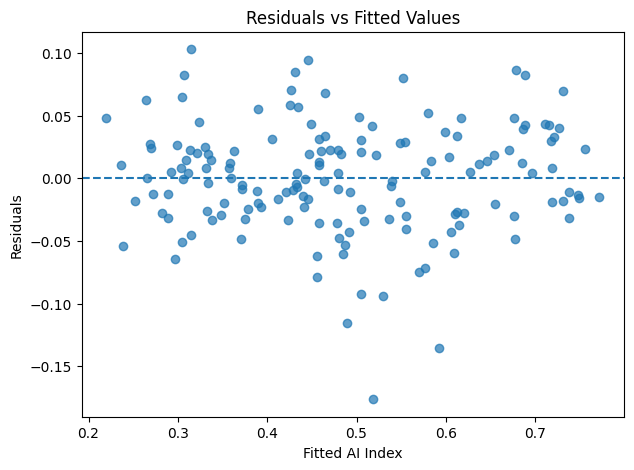

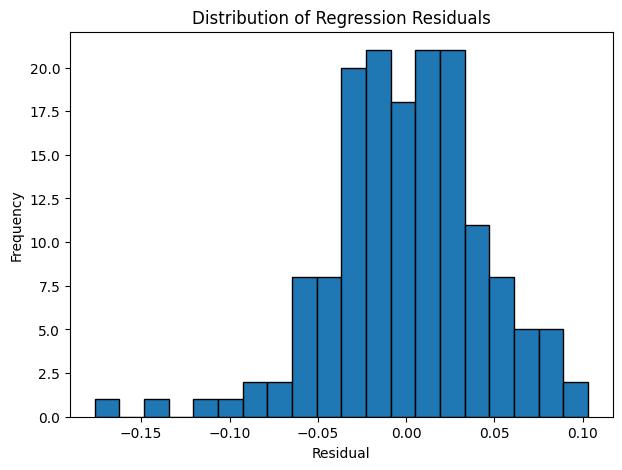

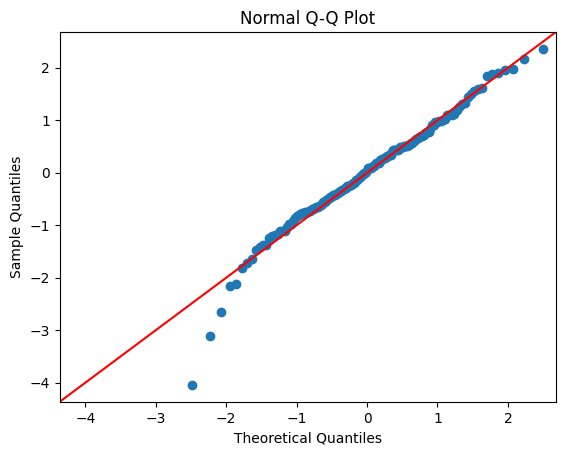

In [ ]:


fitted = model_full.fittedvalues
residuals = model_full.resid

# Residuals versus fitted values
plt.figure(figsize=(7, 5))
plt.scatter(fitted, residuals, alpha=0.7)
plt.axhline(0, linestyle="--")
plt.xlabel("Fitted AI Index")
plt.ylabel("Residuals")
plt.title("Residuals vs Fitted Values")
plt.show()

# Residual distribution
plt.figure(figsize=(7, 5))
plt.hist(residuals, bins=20, edgecolor="black")
plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.title("Distribution of Regression Residuals")
plt.show()

# Normal Q-Q plot
sm.qqplot(residuals, line="45", fit=True)
plt.title("Normal Q-Q Plot")
plt.show()


In [ ]:

formula_interaction = (
    'Q("AI Index") ~ '
    'hc + Subscriptions + log_GDP_emp + Internet + '
    'log_Mobile + Q("Service share") + '
    'Q("Government Effectiveness") + '
    'C(income_group) * '
    '(hc + Subscriptions + Internet)'
)

model_interaction = smf.ols(
    formula=formula_interaction,
    data=reg_df
).fit(cov_type="HC3")

print(model_interaction.summary())


                            OLS Regression Results                            
Dep. Variable:          Q("AI Index")   R-squared:                       0.922
Model:                            OLS   Adj. R-squared:                  0.912
Method:                 Least Squares   F-statistic:                     120.0
Date:                Mon, 26 Oct 2026   Prob (F-statistic):           3.67e-75
Time:                        16:23:48   Log-Likelihood:                 274.36
No. Observations:                 156   AIC:                            -508.7
Df Residuals:                     136   BIC:                            -447.7
Df Model:                          19                                         
Covariance Type:                  HC3                                         
                                                           coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------

In [ ]:


# Identify all interaction coefficients for the four selected predictors
interaction_names = [
    name for name in model_interaction.params.index
    if ":" in name
    and any(
        name.endswith(":" + predictor)
        or name.endswith(":" + 'Q("' + predictor + '")')
        for predictor in [
            "hc", "Subscriptions", "Internet"
        ]
    )
]

print("Interaction coefficients found:")
print(interaction_names)

if interaction_names:
    param_names = list(model_interaction.params.index)
    R = np.zeros((len(interaction_names), len(param_names)))

    for i, name in enumerate(interaction_names):
        R[i, param_names.index(name)] = 1

    joint_interaction_test = model_interaction.wald_test(R, scalar=True)
    print("\nJoint interaction test:")
    print(joint_interaction_test)
else:
    print("No interaction coefficients were identified.")
    print("Inspect model_interaction.params.index to check the names.")


Interaction coefficients found:
['C(income_group)[T.Low income]:hc', 'C(income_group)[T.Lower middle income]:hc', 'C(income_group)[T.Upper middle income]:hc', 'C(income_group)[T.Low income]:Subscriptions', 'C(income_group)[T.Lower middle income]:Subscriptions', 'C(income_group)[T.Upper middle income]:Subscriptions', 'C(income_group)[T.Low income]:Internet', 'C(income_group)[T.Lower middle income]:Internet', 'C(income_group)[T.Upper middle income]:Internet']

Joint interaction test:
<Wald test (chi2): statistic=12.187929269738314, p-value=0.20292093004083242, df_denom=9>


In [ ]:

def test_predictor_interactions(model, predictor):
    names = list(model.params.index)

    matches = [
        name for name in names
        if ":" in name and (
            name.endswith(":" + predictor)
            or name.endswith(':' + 'Q("' + predictor + '")')
        )
    ]

    if not matches:
        return {
            "Predictor": predictor,
            "Interaction terms": 0,
            "Wald statistic": np.nan,
            "p-value": np.nan
        }

    R = np.zeros((len(matches), len(names)))

    for i, name in enumerate(matches):
        R[i, names.index(name)] = 1

    test = model.wald_test(R, scalar=True)

    return {
        "Predictor": predictor,
        "Interaction terms": len(matches),
        "Wald statistic": float(np.asarray(test.statistic).squeeze()),
        "p-value": float(np.asarray(test.pvalue).squeeze())
    }

interaction_tests = pd.DataFrame([
    test_predictor_interactions(model_interaction, predictor)
    for predictor in [
        "hc", "Subscriptions", "Internet"
    ]
])

display(interaction_tests.round(4))


,Predictor,Interaction terms,Wald statistic,p-value
0,hc,3,2.9026,0.4069
1,Subscriptions,3,4.7362,0.1922
2,Internet,3,3.8938,0.2732


In [ ]:

model_comparison = pd.DataFrame({
    "Model": ["Full baseline", "Full with interactions"],
    "Observations": [
        int(model_full.nobs),
        int(model_interaction.nobs)
    ],
    "Parameters": [
        len(model_full.params),
        len(model_interaction.params)
    ],
    "R-squared": [
        model_full.rsquared,
        model_interaction.rsquared
    ],
    "Adjusted R-squared": [
        model_full.rsquared_adj,
        model_interaction.rsquared_adj
    ],
    "AIC": [model_full.aic, model_interaction.aic],
    "BIC": [model_full.bic, model_interaction.bic]
})

display(model_comparison.round(4))


,Model,Observations,Parameters,R-squared,Adjusted R-squared,AIC,BIC
0,Full baseline,156,11,0.9150,0.9091,-512.5033,-478.9549
1,Full with interactions,156,20,0.9224,0.9115,-508.7210,-447.7239


### Clustering

In [ ]:
# Use the existing cleaned dataset
cluster_df = reg_df.copy()

cluster_vars = [
    "AI Index",
    "hc",
    "Subscriptions",
    "log_GDP_emp",
    "Internet",
    "log_Mobile",
    "Service share",
    "Government Effectiveness"
]

# Ensure all clustering variables are numeric
for col in cluster_vars:
    cluster_df[col] = pd.to_numeric(
        cluster_df[col], errors="coerce"
    )

print("Missing values:")
print(cluster_df[cluster_vars].isna().sum())

print("\nIncome-group counts:")
print(cluster_df["income_group"].value_counts())


Missing values:
AI Index                    0
hc                          0
Subscriptions               0
log_GDP_emp                 0
Internet                    0
log_Mobile                  0
Service share               0
Government Effectiveness    0
dtype: int64

Income-group counts:
income_group
High income            56
Upper middle income    45
Lower middle income    38
Low income             17
Name: count, dtype: int64


In [ ]:

income_groups = [
    "High income",
    "Upper middle income",
    "Lower middle income",
    "Low income"
]

cluster_results = {}
silhouette_results = []

for group in income_groups:
    subset = cluster_df.loc[
        cluster_df["income_group"] == group
    ].copy()

    X = subset[cluster_vars].to_numpy()

    # Standardise within this income group
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    # Ward linkage using Euclidean distance
    Z = linkage(X_scaled, method="ward", metric="euclidean")

    # Candidate cluster counts
    max_k = min(5, len(subset) - 1)

    for k in range(2, max_k + 1):
        labels = AgglomerativeClustering(
            n_clusters=k,
            linkage="ward",
            metric="euclidean"
        ).fit_predict(X_scaled)

        score = silhouette_score(X_scaled, labels)

        silhouette_results.append({
            "Income group": group,
            "Clusters (k)": k,
            "Silhouette score": score
        })

    cluster_results[group] = {
        "data": subset,
        "X_scaled": X_scaled,
        "linkage": Z,
        "scaler": scaler
    }

silhouette_table = pd.DataFrame(silhouette_results)

display(
    silhouette_table.sort_values(
        ["Income group", "Silhouette score"],
        ascending=[True, False]
    ).round(4)
)


,Income group,Clusters (k),Silhouette score
0,High income,2,0.2417
1,High income,3,0.2318
3,High income,5,0.2112
2,High income,4,0.2087
12,Low income,2,0.2949
15,Low income,5,0.1928
13,Low income,3,0.1761
14,Low income,4,0.1735
10,Lower middle income,4,0.1910
8,Lower middle income,2,0.1903


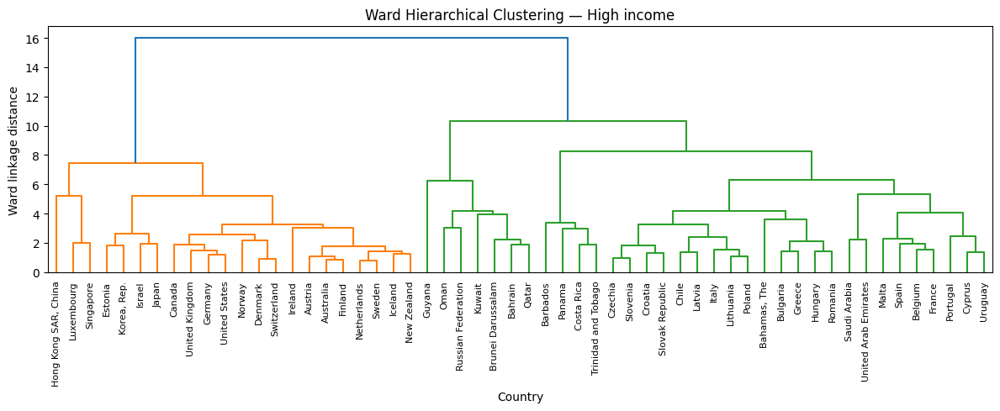

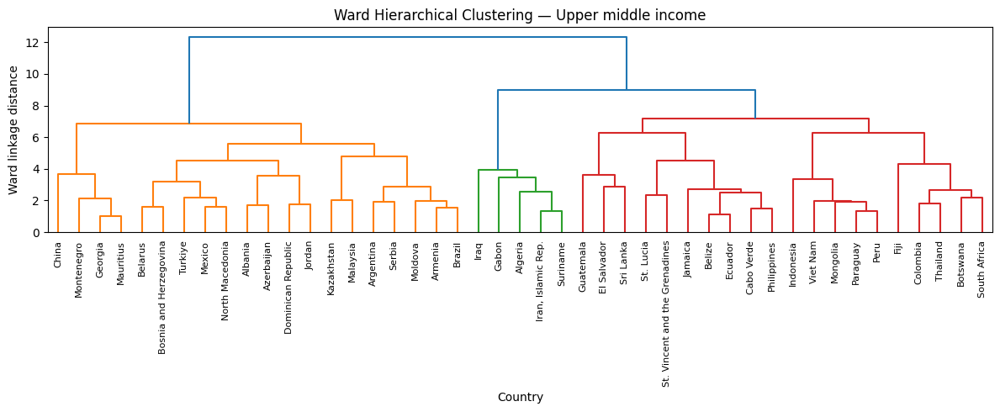

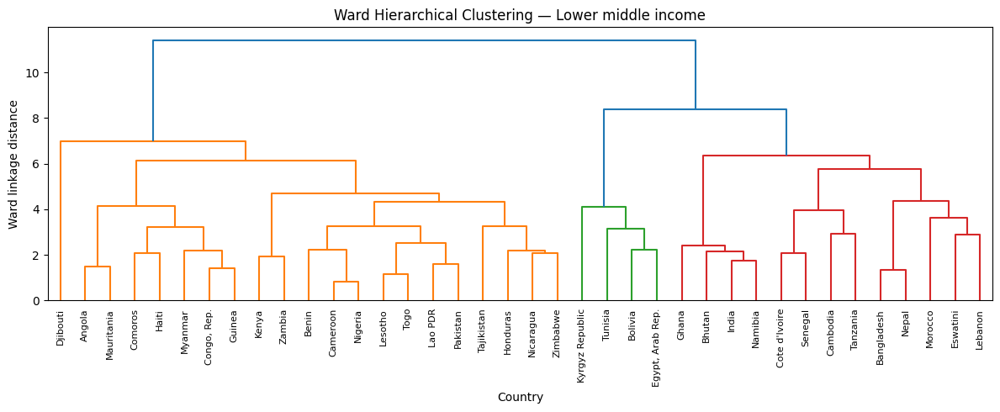

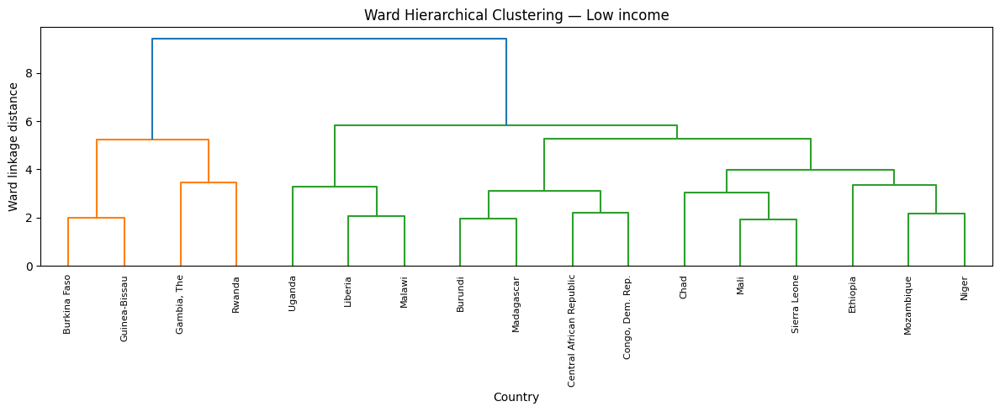

In [ ]:

for group in income_groups:
    result = cluster_results[group]
    subset = result["data"]
    Z = result["linkage"]

    plt.figure(figsize=(12, 5))
    dendrogram(
        Z,
        labels=subset["country"].astype(str).to_numpy(),
        leaf_rotation=90,
        leaf_font_size=8
    )
    plt.title(f"Ward Hierarchical Clustering — {group}")
    plt.xlabel("Country")
    plt.ylabel("Ward linkage distance")
    plt.tight_layout()
    plt.show()


In [ ]:

chosen_k = {
    "High income": 2,
    "Upper middle income": 3,
    "Lower middle income": 2,
    "Low income": 2
}

clustered_groups = []

for group in income_groups:
    result = cluster_results[group]
    subset = result["data"].copy()
    X_scaled = result["X_scaled"]

    model = AgglomerativeClustering(
        n_clusters=chosen_k[group],
        linkage="ward",
        metric="euclidean"
    )

    subset["cluster"] = model.fit_predict(X_scaled) + 1
    clustered_groups.append(subset)

clustered_df = pd.concat(clustered_groups).sort_index()

print("Total countries clustered:", len(clustered_df))

display(
    clustered_df.groupby(
        ["income_group", "cluster"]
    ).size().rename("Countries").reset_index()
)


Total countries clustered: 156


,income_group,cluster,Countries
0,High income,1,34
1,High income,2,22
2,Low income,1,13
3,Low income,2,4
4,Lower middle income,1,17
5,Lower middle income,2,21
6,Upper middle income,1,20
7,Upper middle income,2,20
8,Upper middle income,3,5


In [ ]:


cluster_profiles = (
    clustered_df
    .groupby(["income_group", "cluster"])[cluster_vars]
    .mean()
    .round(3)
)

display(cluster_profiles)

print("\nCluster sizes:")
display(
    clustered_df.groupby(
        ["income_group", "cluster"]
    ).size().rename("Countries").reset_index()
)


AI Index     hc  Subscriptions  log_GDP_emp  \
income_group        cluster                                                
High income         1           0.574  3.198         30.487       11.422   
                    2           0.739  3.600         38.720       11.773   
Low income          1           0.289  1.722          0.125        8.487   
                    2           0.344  1.588          0.429        9.009   
Lower middle income 1           0.401  2.305          5.170       10.057   
                    2           0.325  2.192          1.597        9.616   
Upper middle income 1           0.446  2.742         12.102       10.409   
                    2           0.513  2.992         24.136       10.870   
                    3           0.352  2.712         12.554       10.999   

                             Internet  log_Mobile  Service share  \
income_group        cluster                                        
High income         1          89.414       4.889         60.367   
                    2          94.945       4.910         67.331   
Low income          1          18.598       4.176         40.601   
                    2          32.902       4.722         49.131   
Lower middle income 1          64.834       4.712         49.205   
                    2          44.566       4.482         48.926   
Upper middle income 1          74.389       4.941         57.715   
                    2          86.384       4.796         56.368   
                    3          79.463       4.863         44.697   

                             Government Effectiveness  
income_group        cluster                            
High income         1                           0.681  
                    2                           1.694  
Low income          1                          -1.014  
                    2                          -0.594  
Lower middle income 1                          -0.284  
                    2                          -0.868  
Upper middle income 1                           0.010  
                    2                           0.123  
                    3                          -0.678


Cluster sizes:


,income_group,cluster,Countries
0,High income,1,34
1,High income,2,22
2,Low income,1,13
3,Low income,2,4
4,Lower middle income,1,17
5,Lower middle income,2,21
6,Upper middle income,1,20
7,Upper middle income,2,20
8,Upper middle income,3,5


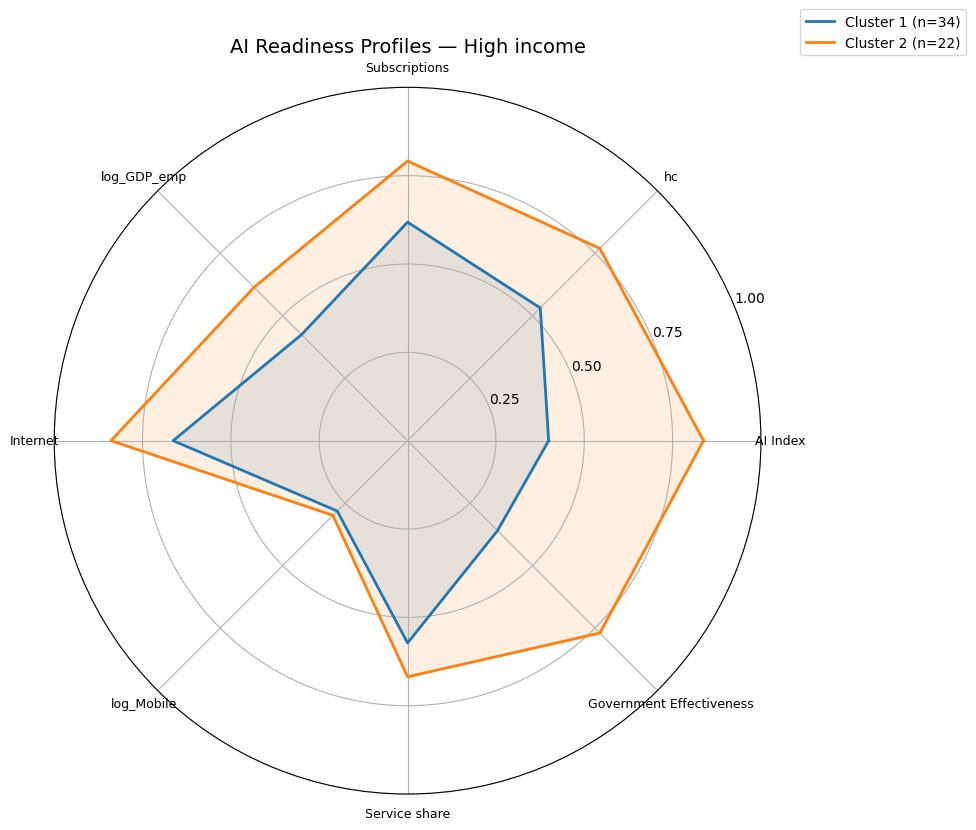

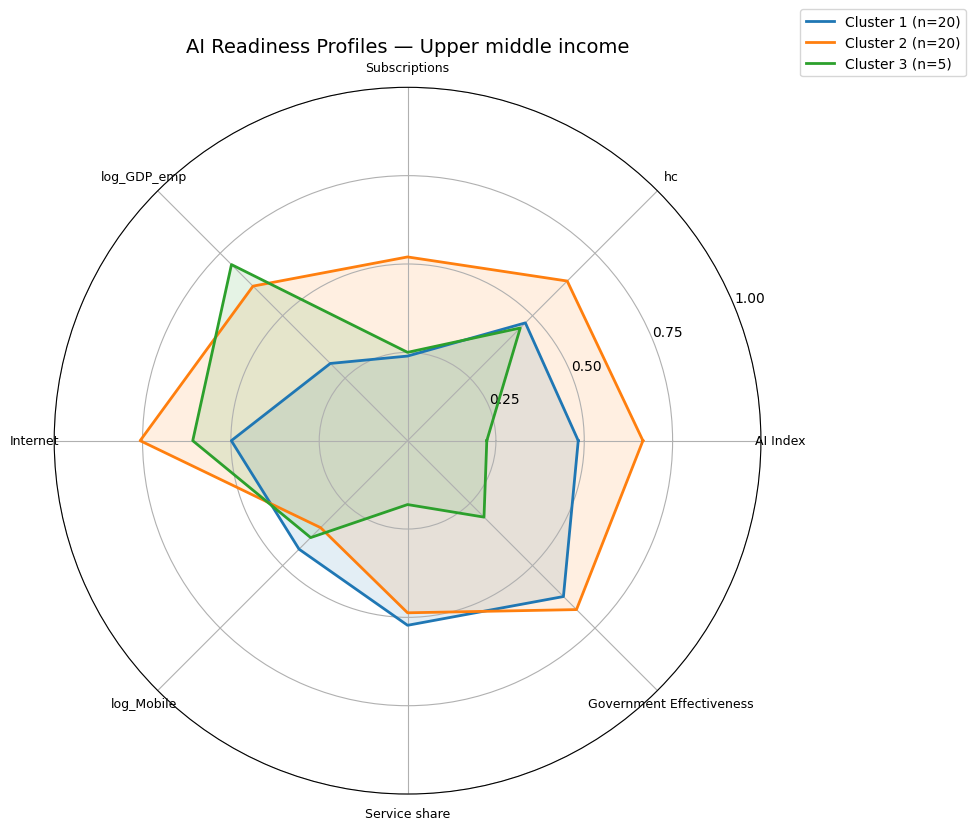

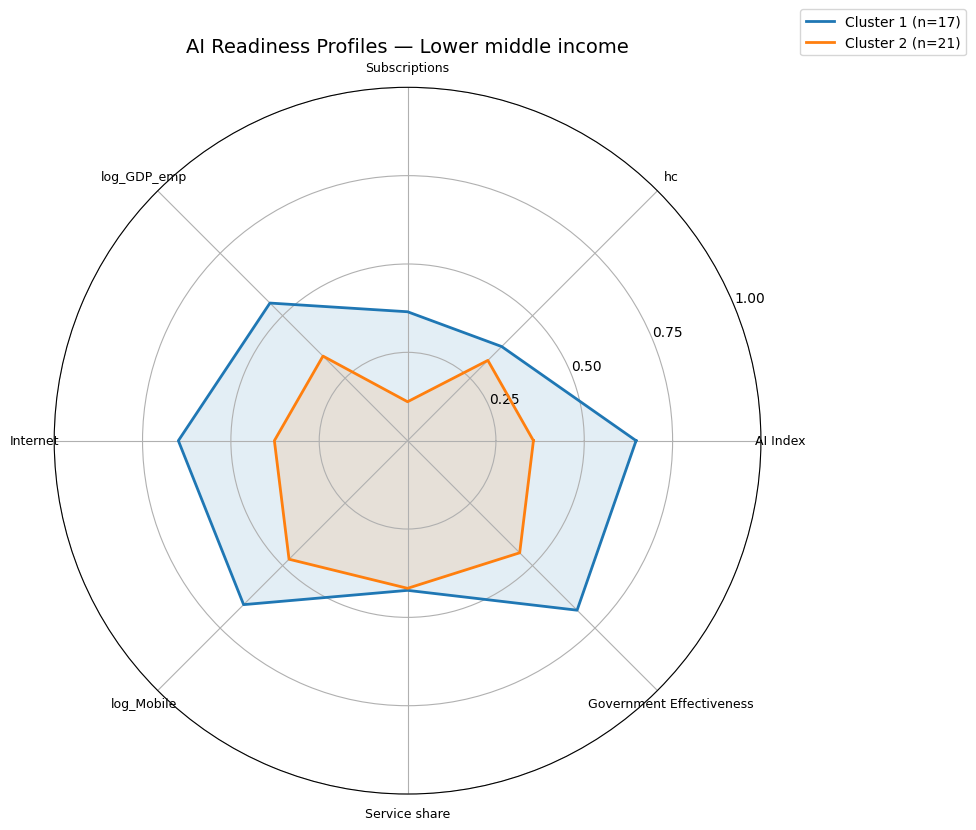

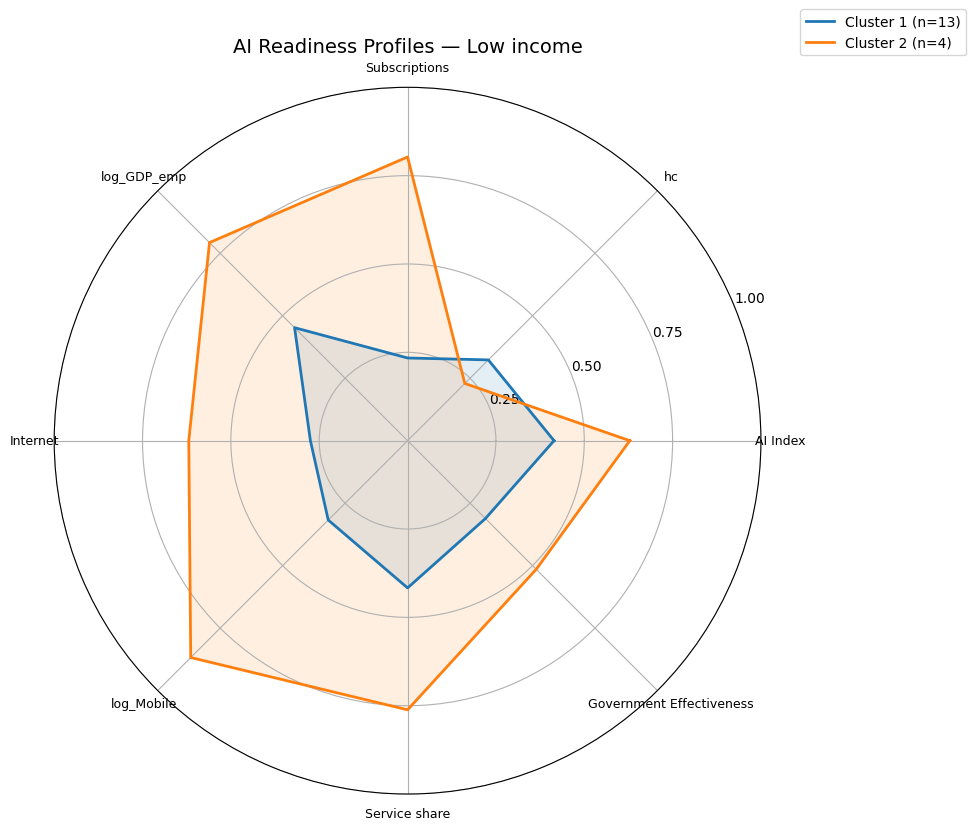

In [ ]:


income_groups = [
    "High income",
    "Upper middle income",
    "Lower middle income",
    "Low income"
]

# Copy the final cluster assignments
radar_df = clustered_df.copy()

# Convert variables to numeric
for col in cluster_vars:
    radar_df[col] = pd.to_numeric(radar_df[col], errors="coerce")

# Create one radar chart per income group
for group in income_groups:

    subset = radar_df[
        radar_df["income_group"] == group
    ].copy()

    # Scale each variable within this income group to 0–1.
    # 0 = lowest observed value; 1 = highest observed value.
    scaled = subset[cluster_vars].copy()

    mins = scaled.min()
    maxs = scaled.max()
    ranges = maxs - mins

    # Handle any variable with no variation
    ranges = ranges.replace(0, 1)

    scaled = (scaled - mins) / ranges

    scaled["cluster"] = subset["cluster"].to_numpy()

    # Mean scaled profile for each cluster
    profiles = scaled.groupby("cluster")[cluster_vars].mean()

    # Number of countries per cluster
    counts = subset.groupby("cluster")["country"].count()

    labels = cluster_vars
    num_vars = len(labels)

    angles = np.linspace(
        0, 2 * np.pi, num_vars, endpoint=False
    ).tolist()
    angles += angles[:1]

    fig, ax = plt.subplots(
        figsize=(10, 10),
        subplot_kw={"polar": True}
    )

    for cluster_id, row in profiles.iterrows():

        values = row.tolist()
        values += values[:1]

        ax.plot(
            angles,
            values,
            linewidth=2,
            label=f"Cluster {cluster_id} (n={counts[cluster_id]})"
        )

        ax.fill(
            angles,
            values,
            alpha=0.12
        )

    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(labels, fontsize=9)

    ax.set_ylim(0, 1)
    ax.set_yticks([0.25, 0.50, 0.75, 1.00])
    ax.set_yticklabels(["0.25", "0.50", "0.75", "1.00"])

    ax.set_title(
        f"AI Readiness Profiles — {group}",
        size=14,
        pad=25
    )

    ax.legend(
        loc="upper right",
        bbox_to_anchor=(1.30, 1.12)
    )

    plt.tight_layout()
    plt.show()


In [ ]:
clustered_df

,country,AI Index,rtfpna,hc,Subscriptions,GDP_emp,Internet,Industry share,Mobile connectivity,Service share,Government Effectiveness,Regulatory Quality,income_group,log_GDP_emp,log_Mobile,AI_z,AI_z_group,cluster
0,Albania,0.526793,1.02,3.02,22.504859,43306.514661,83.135592,23.160712,92.997327,47.664991,0.293429,0.063251,Upper middle income,10.676058,4.532571,0.283844,0.841443,2
1,Algeria,0.370439,0.99,2.51,12.008684,59596.426112,76.197601,37.547655,111.606236,45.547680,-0.355561,-0.785643,Upper middle income,10.995351,4.714977,-0.757854,-1.310548,3
2,Angola,0.259659,1.00,1.54,0.373669,24097.403310,37.885899,35.701247,70.051959,43.554416,-0.828703,-0.904342,Lower middle income,10.089859,4.249237,-1.495915,-1.649913,2
3,Argentina,0.473809,0.97,3.16,25.358073,59860.608685,89.228972,25.172211,137.706087,53.199074,0.061473,-0.506513,Upper middle income,10.999774,4.925122,-0.069152,0.112205,2
4,Armenia,0.492887,1.11,3.16,18.545808,45895.738008,79.996630,22.880096,134.519957,60.345032,-0.163441,0.096441,Upper middle income,10.734128,4.901713,0.057949,0.374777,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
155,United States,0.771269,0.99,3.83,38.093925,150827.869327,93.525597,24.083085,112.410911,63.748307,1.358524,1.430686,High income,11.923895,4.722161,1.912654,1.324750,2
156,Uruguay,0.548641,0.99,3.01,32.403210,64620.714229,90.925903,16.878318,141.719487,65.754060,0.853985,0.737625,High income,11.076290,4.953850,0.429408,-0.909306,1
158,Viet Nam,0.481869,0.99,2.74,22.680668,24493.070282,78.080000,37.593288,130.991429,42.280320,-0.179404,-0.279432,Upper middle income,10.106146,4.875132,-0.015458,0.223130,1
160,Zambia,0.370720,1.06,2.77,0.681390,10849.814829,16.450701,35.107778,102.061565,56.816764,-0.562821,-0.465492,Lower middle income,9.291903,4.625576,-0.755980,0.192712,2


In [ ]:
# Print countries in each cluster, grouped by income group

for income in ["High income", "Upper middle income",
               "Lower middle income", "Low income"]:

    # Fix: use clustered_df instead of reg_df because clustered_df has the 'cluster' column
    group_df = clustered_df[clustered_df["income_group"] == income]

    print(f"\n{'=' * 60}")
    print(f"{income.upper()}")
    print('=' * 60)

    for cluster_num in sorted(group_df["cluster"].dropna().unique()):
        countries = (
            group_df.loc[group_df["cluster"] == cluster_num, "country"]
            .sort_values()
            .tolist()
        )

        print(f"\nCluster {cluster_num} (n={len(countries)}):")
        print(", ".join(countries))


HIGH INCOME

Cluster 1 (n=34):
Bahamas, The, Bahrain, Barbados, Belgium, Brunei Darussalam, Bulgaria, Chile, Costa Rica, Croatia, Cyprus, Czechia, France, Greece, Guyana, Hungary, Italy, Kuwait, Latvia, Lithuania, Malta, Oman, Panama, Poland, Portugal, Qatar, Romania, Russian Federation, Saudi Arabia, Slovak Republic, Slovenia, Spain, Trinidad and Tobago, United Arab Emirates, Uruguay

Cluster 2 (n=22):
Australia, Austria, Canada, Denmark, Estonia, Finland, Germany, Hong Kong SAR, China, Iceland, Ireland, Israel, Japan, Korea, Rep., Luxembourg, Netherlands, New Zealand, Norway, Singapore, Sweden, Switzerland, United Kingdom, United States

UPPER MIDDLE INCOME

Cluster 1 (n=20):
Belize, Botswana, Cabo Verde, Colombia, Ecuador, El Salvador, Fiji, Guatemala, Indonesia, Jamaica, Mongolia, Paraguay, Peru, Philippines, South Africa, Sri Lanka, St. Lucia, St. Vincent and the Grenadines, Thailand, Viet Nam

Cluster 2 (n=20):
Albania, Argentina, Armenia, Azerbaijan, Belarus, Bosnia and Herzego